# `ratio_study` - 01 Basics

### Ratio studies for Computer Assisted Mass Appraisal (CAMA), in Python

*Developed by **ASMA-DS**, the Data Science team within the Assessment Standards and Mass Appraisal department at the Municipal Property Assessment Corporation (MPAC), Ontario, Canada.*

---

This is the first of five notebooks. It covers what ratio studies are (section 1) and the basic workflow (section 2) on the anonymised sample dataset that ships inside the package. Run the cells top to bottom.

Everything here is aligned to the IAAO **Standard on Ratio Studies**. Where the package goes beyond the Standard, the notebook says so.

| Notebook | Covers |
|---|---|
| [01 Basics](01_basics.ipynb) | Sections 1-2: indicators, confidence intervals, compliance checks, IQR trimming, charts, comparisons |
| [02 Spatial](02_spatial.ipynb) | Section 3: ratio maps, Moran's I, hot/cold spots, the VEM map |
| [03 Reporting](03_reporting.ipynb) | Section 4: PDF / XLSX / CSV / PNG output |
| [04 Advanced diagnostics](04_advanced_diagnostics.ipynb) | Sections 5 and 7: ML / SHAP inequity diagnostics and sales-chasing detection |
| [05 Vertical equity](05_vertical_equity.ipynb) | Section 6: VEI, the Vertical Equity Panel, VEM, the Gini family |

All five use the anonymised sample dataset bundled with the package - no data preparation required.
Section numbers are kept from the original single-notebook tour so cross-references still line up.


---
# 1. Introduction

## 1.1 What is a ratio study?

A **ratio study** compares what a jurisdiction *assesses* a property is worth (the **assessed
value**, AV) against a **market value proxy** — usually a screened, time-adjusted sale
price (SP).

The basic unit of analysis is the **assessment-to-sale ratio (ASR)**:

$$\mathrm{ASR} = \frac{\text{assessed value}}{\text{time-adjusted sale price}}$$

Note that:

- **Market value cannot be observed directly.** A single sale is *not* market value; it is
  one observation of it. Ratio study statistics therefore describe a *population* of sales, and
  **cannot be used to judge the valuation of an individual property**.
- **Validity rests on representativeness.** The sample must be representative of the
  population of properties being assessed, and sold and unsold properties must be valued the same way. Where they are
  not — *sales chasing* — the study reports uniformity that does not exist.

From the *distribution* of ASRs across a sample, a ratio study answers three questions:

| Question | Concept | Indicators |
|---|---|---|
| Are we assessing at the right **level**? | Level of valuation | Median, Mean, Weighted Mean |
| Are similar properties treated **alike**? | Uniformity / horizontal equity | COD, COV, Coefficient of Concentration |
| Are lower value and higher value properties treated **alike**? | Vertical equity | **VEI**, PRB, PRD |


## 1.2 Why it matters, and to whom

The primary users are those creating, using or
interpreting ratio studies for mass valuation:

- **Assessment jurisdictions** must demonstrate compliance. A ratio study is the evidence.
- **Valuers and modellers** use it as the acceptance test on a CAMA model, and as a
  diagnostic tool that points *where* the model is deficient.
- **Oversight agencies** use it to monitor, equalize (directly or indirectly), and order
  revaluations.
- **Taxpayers, appeal boards and advocacy groups** use it to detect systematic inequity.
  Note that while a ratio study cannot judge one property, its statistics *can* be used to
  adjust an appealed assessment to the common level.
- **Researchers, journalists, and mortgage-portfolio analysts**.


## 1.3 Motivation for this open-source package

Ratio studies have been run for decades, mostly in spreadsheets, bespoke SAS/SPSS scripts,
or proprietary CAMA modules. 

That has three costs: results are hard to reproduce, newer
literature is slow to reach practice, and every jurisdiction rebuilds the same machinery.

`ratio_study` was built to fix that:

- **IAAO Standard-complete.** The ratio indicators, their acceptable ranges, the
  confidence-interval formulas, the outlier rules and the new VEI.
- **Beyond the Standard.** Additional vertical equity tests (Quintos' Gini /
  Modified Kakwani, Kruskal-Wallis), plus a moving-median measure and ML/SHAP inequity
  diagnostics, in the same API.
- **Reproducible.** One call, seeded, versioned, scriptable in CI. No spreadsheet
  archaeology — a report should let an interested party *replicate* the results.
- **Report-ready.** PDF, Excel, CSV and PNG with automated commentary written for a
  non-technical reader.
- **Backend-agnostic.** pandas, polars or PyArrow in, same backend out, via
  [narwhals](https://github.com/narwhals-dev/narwhals).
- **Open.** GPL-3.0. Jurisdictions should be able to read, audit and improve the code that
  measures the fairness of their own assessments.

---
# 2. Basic ratios

## 2.1 The project page

Source, issue tracker, changelog and the full API documentation live at the project
repository:

> **https://github.com/mpac-asma/ratio_study**

Principal references the package implements:

- IAAO. 2026. *Standard on Ratio Studies draft proposal.* Kansas City
- Gloudemans, R. & Almy, R. 2011. *Fundamentals of Mass Appraisal.* IAAO
- Bonett, D.G. & Seier, E. 2006. "Confidence Intervals for a Coefficient of Dispersion in
  Nonnormal Distributions." *Biometrical Journal* 48(1)
- Clapp, J.M. 1989. "Sample Size in Ratio Studies." *Property Tax Journal* 8(3)
- Quintos, C. 2020, 2021. Gini measure / Gini decomposition. *JPTAA* 17(2), 18(2)
- Efron, B. & Tibshirani, R.J. 1993. *An Introduction to the Bootstrap.*


## 2.2 Load the package

The core install is deliberately light:

```
pip install ratio_study
```

Optional extras switch on the heavier features
used later in this notebook:

| Extra | Enables | Section |
|---|---|---|
| `ratio_study[spatial]` | ratio heat maps, Moran's I | 3 |
| `ratio_study[ml]` | ASR predictability / SHAP diagnostics | 5 |
| `ratio_study[interactive]` | Plotly vertical-equity charts | 6 |

Install everything this notebook needs with:

```
pip install "ratio_study[spatial,ml,interactive]"
```

In [1]:
# Uncomment on first run.
# %pip install "ratio_study[spatial,ml,interactive]"

In [2]:
import ratio_study as rs
import pandas as pd
import numpy as np
from pathlib import Path

# inline plotting must be enabled AFTER importing ratio_study
%matplotlib inline

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

sample_df = rs.load_sample_dataset()

MARKET_VALUE = 'time_adjusted_sale_price'   # the market value proxy
ASSESSMENT   = 'assessment_value_new'       # the value under test (current CAMA model)
PRIOR_MODEL  = 'assessment_value_old'       # a previous model, for comparisons

results_directory = Path().resolve()   # outputs are written here
print('results will be written to:', results_directory)

print('ratio_study version:', rs.__version__)
print(f'{len(sample_df):,} sales, {sample_df.shape[1]} columns')

results will be written to: <path>ratio_study version: 0.4.5
12,583 sales, 19 columns


## 2.3 Load a dataset

The package ships with an anonymised residential sales file so every example below is
reproducible without supplying your own data. 

`load_sample_dataset()` returns a pandas dataframe by
default; pass `'polars'` or `'pyarrow'` to get the same data in another backend.

In [3]:
sample_df = rs.load_sample_dataset()

print(f'{len(sample_df):,} sales, {sample_df.shape[1]} columns')
sample_df.head()

12,583 sales, 19 columns


,sale_month,sale_price,time_adjusted_sale_price,assessment_value_new,assessment_value_old,property_type,structure_type,neighbourhood,sub_neighbourhood,lotsize,frontage,depth,quality_class,condition,living_area,baths,bedrooms,latitude,longitude
0,1,408015,442416,465747.042930,407109.328351,Freehold townhouse/row house,SINGLE FAMILY ROW/TOWN,0,8,0.0000,19.78,108.07,6,average,1631,2.5,3,45.424511,-75.526099
1,1,858862,918680,908491.199293,801526.624705,Single family detached (not on water),SINGLE FAMILY DETACHED,1,7,0.1409,70.17,84.89,7,average,2723,2.5,4,45.364210,-75.694326
2,1,571399,613666,681232.600042,558604.724217,Single family detached (not on water),SINGLE FAMILY DETACHED,1,9,0.0000,50.41,94.60,6,average,2728,2.5,5,45.371878,-75.656543
3,1,1136812,1217586,647431.903709,743123.273982,Single family detached (not on water),SINGLE FAMILY DETACHED,1,7,0.0000,59.92,96.19,6,average,2171,2.5,4,45.372463,-75.681476
4,1,639129,681754,633954.314953,696911.119495,Single family detached (not on water),SINGLE FAMILY DETACHED,2,11,0.0935,49.88,87.44,5,average,1453,1.5,3,45.342802,-75.742005


Two columns carry the study. Name them explicitly rather than relying on argument
position.

In [4]:
MARKET_VALUE = 'time_adjusted_sale_price'   # the market value proxy
ASSESSMENT   = 'assessment_value_new'       # the value under test (current CAMA model)
PRIOR_MODEL  = 'assessment_value_old'       # a previous model, for the comparison in 2.10 of the basics notebook

sample_df[[MARKET_VALUE, ASSESSMENT, PRIOR_MODEL]].describe().round(0)

,time_adjusted_sale_price,assessment_value_new,assessment_value_old
count,12583.0,12583.0,12583.0
mean,485946.0,484455.0,453651.0
std,213177.0,198552.0,183484.0
min,99812.0,81220.0,1041.0
25%,352582.0,358618.0,335289.0
50%,427248.0,424683.0,398928.0
75%,562992.0,561345.0,525045.0
max,7794906.0,4174852.0,3686556.0


Note the denominator is the **time-adjusted** sale price. 

Adjusting sales for time allows one to use sales over multiple years.

## 2.4 Generate basic ratio indicators

One call. `ratios()` computes the indicators, formats them for presentation, and attaches
confidence intervals to the headline measures by default — which the Standard requires:
*every* ratio study should include measures of level, of uniformity, **and** confidence
intervals showing statistical reliability.

In [5]:
br = rs.ratios(sample_df,
          assessment_header=ASSESSMENT,
          market_value_header=MARKET_VALUE)
br

Confidence interval settings  (<-- marks a value you set or is a default setting)
  Mode                  : distribution
  Level                 : 90%
  Indicators            : Median, Mean, Weighted_Mean, CoD, PRB, PRD
  Overall intervals     : on
  Per-group intervals   : off
  Minimum sales per row : 20
  Estimators            : Appendix D closed forms, plus PRB (regression) and PRD (delta method); bootstrap options ignored
VEI quantile method: R7


,Level,Count,Median,Median_ci,Mean,Mean_ci,Weighted_Mean,Weighted_Mean_ci,CoD,CoD_ci,PRB,PRB_ci,PRD,PRD_ci,VEI,VEI_conclusion,VEI_kw_statistic,VEI_kw_pvalue,Inequity_conclusion,Inequity_severity,Inequity_prevalence
0,Overall,"12,583",0.9985,"(0.9968, 1.0001)",1.0089,"(1.0070, 1.0108)",0.9969,"(0.9946, 0.9993)",9.48%,"(9.36%, 9.61%)",-0.0178,"(-0.0216, -0.0139)",1.0120,"(1.0107, 1.0134)",-0.75,Acceptable,103.19,0.00,acceptable,0.00,0.00


### Add stratifications

### Reading the columns

`Level` / `Group` name the stratum, `Count` is the sample size for that row, while the prefix `_ci` indicates a confidence interval.

### Choosing the indicator set

The default is `['Median', 'CoD', 'PRD', 'PRB', 'VEI', 'VEM']`. 

Ask for more by passing the argument 'indicators' with a list of the required indicators.

| Indicator | Family |
|---|---|
| `Median`, `Mean`, `Weighted_Mean` | Level of valuation |
| `CoD` | Uniformity — the recommended measure |
| `CoD_rsd`, `CoV`, `CoC_15`, `FSD` | Other uniformity measures |
| `VEI` | Vertical equity — **the preferred measure** |
| `PRB` | Vertical equity |
| `PRD` | Vertical equity — **being retired** |
| `MKI`, `RRI` | Vertical equity (Gini) |
| `RMSE`, `MAE`, `MAPE` | Accuracy |

In [6]:
ALL_INDICATORS = ['Median', 'Mean', 'Weighted_Mean',
                  'CoD', 'CoD_rsd', 'CoV', 'CoC_15', 'FSD',
                  'VEI', 'PRB', 'PRD', 'VEM', 'MKI', 'RRI',
                  'RMSE', 'MAE', 'MAPE']

full_study = rs.ratios(sample_df,
                       assessment_header=ASSESSMENT,
                       market_value_header=MARKET_VALUE,
                       indicators=ALL_INDICATORS)

full_study         # transposed - one indicator per row, easier to read

Confidence interval settings  (<-- marks a value you set or is a default setting)
  Mode                  : distribution
  Level                 : 90%
  Indicators            : Median, Mean, Weighted_Mean, CoD, PRB, PRD
  Overall intervals     : on
  Per-group intervals   : off
  Minimum sales per row : 20
  Estimators            : Appendix D closed forms, plus PRB (regression) and PRD (delta method); bootstrap options ignored
VEI quantile method: R7


,Level,Count,Median,Median_ci,Mean,Mean_ci,Weighted_Mean,Weighted_Mean_ci,CoD,CoD_ci,CoD_rsd,CoV,CoC_15,FSD,PRB,PRB_ci,PRD,PRD_ci,VEI,VEI_conclusion,VEI_kw_statistic,VEI_kw_pvalue,Inequity_conclusion,Inequity_severity,Inequity_prevalence,RRI,MKI,MKI_pvalue,RMSE,MAE,MAPE
0,Overall,"12,583",0.9985,"(0.9968, 1.0001)",1.0089,"(1.0070, 1.0108)",0.9969,"(0.9946, 0.9993)",9.48%,"(9.36%, 9.61%)",9.71%,12.76%,80.72%,12.87% (0.000),-0.0178,"(-0.0216, -0.0139)",1.0120,"(1.0107, 1.0134)",-0.75,Acceptable,103.19,0.00,acceptable,0.00,0.00,2.80%,0.9165,,"77,617","47,192",9.47%


## 2.5 Simplified standard pass checks

`descriptive=True` grades the study against standards and writes a plain-language
comment — **only where an indicator falls short**.

In [7]:
rs.ratios(sample_df,
          assessment_header=ASSESSMENT,
          market_value_header=MARKET_VALUE,
          descriptive=True,
          indicators=['Median', 'CoD', 'PRB'],
          group_by='property_type')

Confidence interval settings  (<-- marks a value you set or is a default setting)
  Mode                  : distribution
  Level                 : 90%
  Indicators            : Median, CoD, PRB   <-- set
  Overall intervals     : on
  Per-group intervals   : off
  Minimum sales per row : 20
  Estimators            : Appendix D closed forms, plus PRB (regression) and PRD (delta method); bootstrap options ignored


,Level,Group,Count,Median,Median_ci,CoD,CoD_ci,PRB,PRB_ci,Comments Ratio Study Standard metrics,Median_acceptable,PRB_acceptable,CoD_acceptable
0,Overall,,"12,583",0.9985,"(0.9968, 1.0001)",9.48%,"(9.36%, 9.61%)",-0.0178,"(-0.0216, -0.0139)",,True,True,True
1,property_type,Bed and breakfast,3ø,1.1092,,,,,,Sample too small (3): some ratio indicators co...,False,,
2,property_type,Duplex,354,1.0122,,11.06%,,-0.0736⊥,,PRB suggests a review regarding assessment sta...,True,False,True
3,property_type,Fiveplex,30,0.9712,,9.54%,,-0.0590⊥,,PRB not significant at 95%,True,False,True
4,property_type,Fourplex,70,1.0009,,11.83%,,-0.0462⊥,,PRB not significant at 95%,True,True,True
5,property_type,Freehold townhouse/row house,"2,149",0.9893,,7.15%,,0.0168,,,True,True,True
6,property_type,Group home,1ø,1.1223,,,,,,Sample too small (1): some ratio indicators co...,False,,
7,property_type,Link home,81,0.9951,,7.59%,,-0.0231⊥,,PRB not significant at 95%,True,True,True
8,property_type,Residence with commercial unit,4ø,0.9006,,13.03%,,-0.17385*,,Sample too small (4): some ratio indicators co...,False,False,True
9,property_type,Rooming or boarding house,9ø,0.8909,,21.68%,,-0.09881*,,Small sample (9): indicators may not reliably ...,False,False,False


The comments are gated on the confidence intervals (when available), not just the point estimate.

### Choosing the right standards for your property class

Ratio studies work to the range
for their property class and market profile:

| Property category | Profile | COD range |
|---|---|---|
| Residential improved | general | 5.0 – 15.0 |
| | newer / homogeneous, condominiums | 4.0 – 10.0 |
| | rural, seasonal, manufactured homes | 10.0 – 20.0 |
| Multi-unit apartments | general | 7.0 – 20.0 |
| Commercial / industrial / retail | general | 10.0 – 25.0 |
| Vacant land | general | 10.0 – 20.0 |
| Agricultural land | | 10.0 – 25.0 |

The Standard widens these substantially for **blighted, distressed and emerging** market
areas (e.g. residential 10.0–25.0 distressed, 10.0–35.0 emerging).

Level of valuation should be **0.90 to 1.10** for any class, with a target of 1.00.

In [8]:
# Residential improved, general profile, per the Standard.
# CoD is expressed as a fraction here, so 5.0-15.0 becomes 0.05-0.15.
# set a dictionary with the standards, and pass to ratios()
assessment_standards = {'Median': (0.90, 1.10),     # level of valuation
                        'CoD':    (0.05, 0.15),     # residential improved
                        'VEI':    (-10.0, 10.0),    # preferred measure
                        'PRB':    (-0.05, 0.05),
                        'PRD':    (0.98, 1.03)}     # retiring

rs.ratios(sample_df,
          assessment_header=ASSESSMENT,
          market_value_header=MARKET_VALUE,
          indicators=['Median', 'CoD', 'VEI', 'PRB', 'PRD'],
          descriptive=True,
          assessment_standards=assessment_standards)

Confidence interval settings  (<-- marks a value you set or is a default setting)
  Mode                  : distribution
  Level                 : 90%
  Indicators            : Median, CoD, PRB, PRD   <-- set
  Overall intervals     : on
  Per-group intervals   : off
  Minimum sales per row : 20
  Estimators            : Appendix D closed forms, plus PRB (regression) and PRD (delta method); bootstrap options ignored
VEI quantile method: R7


,Level,Count,Median,Median_ci,CoD,CoD_ci,PRB,PRB_ci,PRD,PRD_ci,VEI,VEI_conclusion,VEI_kw_statistic,VEI_kw_pvalue,Comments Ratio Study Standard metrics,Median_acceptable,CoD_acceptable,VEI_acceptable,PRB_acceptable,PRD_acceptable
0,Overall,"12,583",0.9985,"(0.9968, 1.0001)",9.48%,"(9.36%, 9.61%)",-0.0178,"(-0.0216, -0.0139)",1.0120,"(1.0107, 1.0134)",-0.75,Acceptable,103.19,0.00,,True,True,True,True,True


### Confidence intervals

Overall 95% BCa bootstrap intervals for `Median`, `CoD`, `PRD` and `PRB` are on by
default. Everything about them is adjustable — which indicators, what level, how many
resamplings, and the seed that makes a published number reproducible.

The Standard asks for **90% two-tailed** (or 95% one-tailed) before concluding noncompliance.

In [9]:
rs.ratios(sample_df,
          assessment_header=ASSESSMENT,
          market_value_header=MARKET_VALUE,
          descriptive=True,
          ci_indicators=['Median', 'CoD', 'PRD'],
          ci_conf_level=90,
          ci_seed=7,
          bootstrap_args={'resamplings': 500})

Confidence interval settings  (<-- marks a value you set or is a default setting)
  Mode                  : distribution
  Level                 : 90%
  Indicators            : Median, CoD, PRD   <-- set
  Overall intervals     : on
  Per-group intervals   : off
  Minimum sales per row : 20
  Estimators            : Appendix D closed forms, plus PRB (regression) and PRD (delta method); bootstrap options ignored
VEI quantile method: R7


,Level,Count,Median,Median_ci,Mean,Weighted_Mean,CoD,CoD_ci,PRB,PRB_ci,PRD,PRD_ci,VEI,VEI_conclusion,VEI_kw_statistic,VEI_kw_pvalue,Inequity_conclusion,Inequity_severity,Inequity_prevalence,Comments Ratio Study Standard metrics,Median_acceptable,PRB_acceptable,PRD_acceptable,CoD_acceptable
0,Overall,"12,583",0.9985,"(0.9968, 1.0001)",1.0089,0.9969,9.48%,"(9.36%, 9.61%)",-0.0178,"(-0.0216, -0.0139)",1.0120,"(1.0107, 1.0134)",-0.75,Acceptable,103.19,0.00,acceptable,0.00,0.00,,True,True,True,True


There is a second family of intervals: the **closed-form formulas from the Standard**.

| Statistic | Method |
|---|---|
| Mean | Student's *t* about the mean |
| Median | Rank formula, `j = z·√n / 2` |
| Weighted mean | Ratio-estimator standard error |
| Median, n ≤ 30 | Clapp (1989) binomial interpolation tables |
| COD | Bonett–Seier |

Switch families with one argument. These carry no minimum-sample gate — the binomial
median tables reach down to 5 sales at 90% and 6 at 95% — which is what makes them the
right choice for thin strata.

In [10]:
rs.ratios(sample_df,
          assessment_header=ASSESSMENT,
          market_value_header=MARKET_VALUE,
          indicators=['Median', 'CoD', 'PRD', 'PRB'],
          ci_mode='distribution',
          ci_conf_level=95,
          descriptive=True)

Confidence interval settings  (<-- marks a value you set or is a default setting)
  Mode                  : distribution
  Level                 : 95%   <-- set
  Indicators            : Median, CoD, PRB, PRD   <-- set
  Overall intervals     : on
  Per-group intervals   : off
  Minimum sales per row : 20
  Estimators            : Appendix D closed forms, plus PRB (regression) and PRD (delta method); bootstrap options ignored


,Level,Count,Median,Median_ci,CoD,CoD_ci,PRB,PRB_ci,PRD,PRD_ci,Comments Ratio Study Standard metrics,Median_acceptable,PRB_acceptable,PRD_acceptable,CoD_acceptable
0,Overall,"12,583",0.9985,"(0.9963, 1.0005)",9.48%,"(9.33%, 9.64%)",-0.0178,"(-0.0223, -0.0132)",1.0120,"(1.0104, 1.0136)",,True,True,True,True


### Seeing the settings you did not choose

Most of what governs an interval is a default nobody typed: the level, the method, the
number of resamplings, the size of each resample, the minimum count, the seed. A published
interval can therefore rest on settings that were never reviewed — and the Standard asks a report
to describe *"statistics used, and reliability and proper use of results"*.

`print_ci_settings` (on by default) prints the resolved settings before the study runs, and
marks anything that differs from the package default with `<-- set`, so what you chose is
visually separable from what you inherited. Set it to `False` in loops or CI.

In [11]:
settings_demo = rs.ratios(sample_df,
                          assessment_header=ASSESSMENT,
                          market_value_header=MARKET_VALUE,
                          indicators=['Median', 'CoD', 'PRD', 'PRB'],
                          ci_conf_level=90,
                          ci_seed=7,
                          bootstrap_args={'resamplings': 500, 'method': 'percentile'}
                          , print_ci_settings=True)
settings_demo

Confidence interval settings  (<-- marks a value you set or is a default setting)
  Mode                  : distribution
  Level                 : 90%
  Indicators            : Median, CoD, PRB, PRD   <-- set
  Overall intervals     : on
  Per-group intervals   : off
  Minimum sales per row : 20
  Estimators            : Appendix D closed forms, plus PRB (regression) and PRD (delta method); bootstrap options ignored


,Level,Count,Median,Median_ci,CoD,CoD_ci,PRB,PRB_ci,PRD,PRD_ci
0,Overall,"12,583",0.9985,"(0.9968, 1.0001)",9.48%,"(9.36%, 9.61%)",-0.0178,"(-0.0216, -0.0139)",1.0120,"(1.0107, 1.0134)"


Note the last line of the default summary when no seed is given: *"intervals vary slightly
between runs"*. That is worth acting on before publishing a number — `ci_seed` makes the
interval reproducible, which is what lets a reader replicate the study, as the Standard recommends.

### `bootstrap_resample_pct` — how certain would I be on a smaller sample?

The classical bootstrap draws *n* observations from a sample of *n*, so the interval
estimates the sampling error of the study you actually ran.

`bootstrap_resample_pct` draws fewer — an **m-out-of-n bootstrap**. That answers a different
and very practical question: *what would my confidence interval look like if I had only had
a fraction of these sales?*

That matters because sample size is central to the Standard's guidance. Before a study is designed,
the Standard notes that the required sample size has to be projected from the
dispersion you expect, *"which is not known during the design and planning stage"*. Running
the bootstrap at a reduced draw on last cycle's data is a direct, assumption-free way to
estimate what precision a smaller sample would buy — and whether a thin stratum next year
will produce an interval narrow enough to conclude anything with.

Two details:

- Give it a fraction (`0.2`) or a percentage (`20`); both read the same.
- Each draw is floored at **20 sales** (or *n*, if the sample is smaller than that), so a 20%
  draw from 50 sales takes 20, not 10. Below about 20 the indicators stop meaning anything —
  a COD on 8 sales is noise — and the floor is also the `min_count_threshold` the package
  uses everywhere else.

In [12]:
precision_curve = []
for pct in (1.00, 0.50, 0.25, 0.10, 0.05, 0.01):
    row = rs.ratios(sample_df,
                    assessment_header=ASSESSMENT,
                    market_value_header=MARKET_VALUE,
                    indicators=['Median', 'CoD'],
                    ci_conf_level=90,
                    ci_seed=7,
                    print_ci_settings=False,
                    bootstrap_args={'resamplings': 400, 'resample_pct': pct}).iloc[0]

    low, high = (float(x) for x in row['Median_ci'].strip('()').split(','))
    precision_curve.append({
        'resample %': f'{pct:.0%}',
        'sales drawn': max(20, round(len(sample_df) * pct)),
        'Median': row['Median'],
        'Median 90% CI': row['Median_ci'],
        'CI width': round(high - low, 4),
        'CoD 90% CI': row['CoD_ci'],
    })

pd.DataFrame(precision_curve).set_index('resample %')

,sales drawn,Median,Median 90% CI,CI width,CoD 90% CI
resample %,,,,,
100%,12583,0.9985,"(0.9968, 1.0001)",0.0033,"(9.36%, 9.61%)"
50%,6292,0.9985,"(0.9968, 1.0001)",0.0033,"(9.36%, 9.61%)"
25%,3146,0.9985,"(0.9968, 1.0001)",0.0033,"(9.36%, 9.61%)"
10%,1258,0.9985,"(0.9968, 1.0001)",0.0033,"(9.36%, 9.61%)"
5%,629,0.9985,"(0.9968, 1.0001)",0.0033,"(9.36%, 9.61%)"
1%,126,0.9985,"(0.9968, 1.0001)",0.0033,"(9.36%, 9.61%)"


The point estimate never moves — resampling cannot change the sample statistic. What moves
is the **width**, and it widens roughly as $\sqrt{n/m}$: quartering the draw about doubles the
interval.

Read the table as a sample-size planning tool. If a 25% draw still gives a median interval
tight enough to test against the Standard's range of 0.90–1.10, then a stratum a quarter this
size would also support a conclusion. If a 5% draw does not, then thin strata next cycle
will need the remedies the Standard suggests — a longer sales period, combined strata, or independent
value estimates.

The floor is visible at the bottom of the table: 1% of 12,583 is 126, comfortably above 20,
but on a 50-sale stratum the same 1% request would draw 20.

In [13]:
# On a small stratum the floor binds: 20% and 40% both draw 20 sales,
# so with one seed they produce exactly the same interval.
small = sample_df.head(50)
for pct in (0.20, 0.40):
    ci = rs.ratios(small, assessment_header=ASSESSMENT, market_value_header=MARKET_VALUE,
                   indicators=['Median'], ci_conf_level=90, ci_seed=3, print_ci_settings=False,
                   bootstrap_args={'resamplings': 300, 'resample_pct': pct}).iloc[0]['Median_ci']
    print(f'n=50, resample_pct={pct:.0%} -> draw {max(20, round(50 * pct)):>2} sales, '
          f'Median 90% CI {ci}')

n=50, resample_pct=20% -> draw 20 sales, Median 90% CI (0.9791, 1.0383)
n=50, resample_pct=40% -> draw 20 sales, Median 90% CI (0.9791, 1.0383)


## 2.6 Horizontal Equity Analysis - stratification

An overall study that passes can still hide a stratum that badly fails. `group_by`
runs the whole study again within each stratum and stacks the results under the overall
row. This is what the Standard calls stratification.

Two standards apply *between* strata:

- each stratum's level within **5 percent** — not 5 percentage points — of the overall level
- classes not provably differing from each other by more than **10 percent**

In [14]:
rs.ratios(sample_df,
          assessment_header=ASSESSMENT,
          market_value_header=MARKET_VALUE,
          group_by='property_type',
          descriptive=True)

Confidence interval settings  (<-- marks a value you set or is a default setting)
  Mode                  : distribution
  Level                 : 90%
  Indicators            : Median, Mean, Weighted_Mean, CoD, PRB, PRD
  Overall intervals     : on
  Per-group intervals   : off
  Minimum sales per row : 20
  Estimators            : Appendix D closed forms, plus PRB (regression) and PRD (delta method); bootstrap options ignored
VEI quantile method: R7


,Level,Group,Count,Median,Median_ci,Mean,Mean_ci,Weighted_Mean,Weighted_Mean_ci,CoD,CoD_ci,PRB,PRB_ci,PRD,PRD_ci,VEI,VEI_conclusion,VEI_kw_statistic,VEI_kw_pvalue,Inequity_conclusion,Inequity_severity,Inequity_prevalence,Comments Ratio Study Standard metrics,Median_acceptable,PRB_acceptable,PRD_acceptable,CoD_acceptable
0,Overall,,"12,583",0.9985,"(0.9968, 1.0001)",1.0089,"(1.0070, 1.0108)",0.9969,"(0.9946, 0.9993)",9.48%,"(9.36%, 9.61%)",-0.0178,"(-0.0216, -0.0139)",1.0120,"(1.0107, 1.0134)",-0.75,Acceptable,103.19,0.00,acceptable,0.00,0.00,,True,True,True,True
1,property_type,Bed and breakfast,3ø,1.1092,,1.1182,,1.1049,,,,,,,,0.00,Sample size too small,,,,,,Sample too small (3): some ratio indicators co...,False,,,
2,property_type,Duplex,354,1.0122,,1.0222,,1.0022,,11.06%,,-0.0736⊥,,1.0199,,-9.29,Acceptable,21.21,0.00,Regressivity,25.79,1.41,PRB suggests a review regarding assessment sta...,True,False,True,True
3,property_type,Fiveplex,30,0.9712,,0.9921,,0.9781,,9.54%,,-0.0590⊥,,1.0144,,0.17,Acceptable,0.27,0.60,Regressivity,19.67,6.67,PRB not significant at 95%,True,False,True,True
4,property_type,Fourplex,70,1.0009,,1.0179,,0.9957,,11.83%,,-0.0462⊥,,1.0222,,-3.18,Acceptable,1.14,0.77,Inconclusive,0.00,0.00,PRB not significant at 95%,True,True,True,True
5,property_type,Freehold townhouse/row house,"2,149",0.9893,,0.9963,,0.9934,,7.15%,,0.0168,,1.0029,,3.93,Acceptable,60.31,0.00,acceptable,0.00,0.00,,True,True,True,True
6,property_type,Group home,1ø,1.1223,,1.1223,,1.1223,,,,,,,,0.00,Sample size too small,,,,,,Sample too small (1): some ratio indicators co...,False,,,
7,property_type,Link home,81,0.9951,,0.9952,,0.9863,,7.59%,,-0.0231⊥,,1.0090,,0.62,Acceptable,4.57,0.21,acceptable,0.00,0.00,PRB not significant at 95%,True,True,True,True
8,property_type,Residence with commercial unit,4ø,0.9006,,0.9106,,0.8736,,13.03%,,-0.17385*,,1.0424,,0.00,Sample size too small,,,,,,Sample too small (4): some ratio indicators co...,False,False,False,True
9,property_type,Rooming or boarding house,9ø,0.8909,,0.9592,,0.9120,,21.68%,,-0.09881*,,1.0518,,0.00,Sample size too small,,,,,,Small sample (9): indicators may not reliably ...,False,False,False,False


Pass a list to get several independent groupings in one table, and a **nested list** to get
the cross-tabulation. The Standard recommends stratifying on more than one characteristic
simultaneously when evaluating valuation quality.

In [15]:
nested = rs.ratios(sample_df,
                   assessment_header=ASSESSMENT,
                   market_value_header=MARKET_VALUE,
                   group_by=['quality_class',
                             'property_type',
                             ['quality_class', 'property_type']],
                   descriptive=True)

nested

Confidence interval settings  (<-- marks a value you set or is a default setting)
  Mode                  : distribution
  Level                 : 90%
  Indicators            : Median, Mean, Weighted_Mean, CoD, PRB, PRD
  Overall intervals     : on
  Per-group intervals   : off
  Minimum sales per row : 20
  Estimators            : Appendix D closed forms, plus PRB (regression) and PRD (delta method); bootstrap options ignored
VEI quantile method: R7


,Level,Group,Count,Median,Median_ci,Mean,Mean_ci,Weighted_Mean,Weighted_Mean_ci,CoD,CoD_ci,PRB,PRB_ci,PRD,PRD_ci,VEI,VEI_conclusion,VEI_kw_statistic,VEI_kw_pvalue,Inequity_conclusion,Inequity_severity,Inequity_prevalence,Comments Ratio Study Standard metrics,Median_acceptable,PRB_acceptable,PRD_acceptable,CoD_acceptable
0,Overall,,"12,583",0.9985,"(0.9968, 1.0001)",1.0089,"(1.0070, 1.0108)",0.9969,"(0.9946, 0.9993)",9.48%,"(9.36%, 9.61%)",-0.0178,"(-0.0216, -0.0139)",1.0120,"(1.0107, 1.0134)",-0.75,Acceptable,103.19,0.00,acceptable,0.00,0.00,,True,True,True,True
1,quality_class,0,172,0.9982,,1.0558,,0.9807,,22.50%⊥,,-0.1152⊥,,1.0766⊥,,-19.37,Acceptable,11.49,0.01,Regressivity,38.52,16.86,CoD suggests a review regarding assessment sta...,True,False,False,False
2,quality_class,1,1ø,0.8916,,0.8916,,0.8916,,,,,,,,0.00,Sample size too small,,,,,,Sample too small (1): some ratio indicators co...,False,,,
3,quality_class,2,3ø,1.0159,,1.0969,,1.0825,,,,,,,,0.00,Sample size too small,,,,,,Sample too small (3): some ratio indicators co...,True,,,
4,quality_class,3,172,1.0118,,1.0193,,0.9993,,13.17%,,-0.0909⊥,,1.0200,,-9.27,Acceptable,13.17,0.00,Inconclusive,0.00,0.00,PRB suggests a review regarding assessment sta...,True,False,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99,"quality_class, property_type","9, Duplex",1ø,1.1321,,1.1321,,1.1321,,,,,,,,0.00,Sample size too small,,,,,,Sample too small (1): some ratio indicators co...,False,,,
100,"quality_class, property_type","9, Freehold townhouse/row house",8ø,0.9665,,1.0037,,0.9655,,15.68%,,-0.7813,,1.0396,,0.00,Sample size too small,,,,,,Small sample (8): indicators may not reliably ...,True,False,False,True
101,"quality_class, property_type","9, Semi-detached residential (separate ownership)",7ø,1.0697,,1.1020,,1.1028,,9.30%,,0.39288*,,0.9992,,0.00,Sample size too small,,,,,,Small sample (7): indicators may not reliably ...,False,False,True,True
102,"quality_class, property_type","9, Single family detached (not on water)",57,1.0498⊥,,1.0630,,1.0511,,11.32%,,-0.0091⊥,,1.0113,,-0.74,Acceptable,0.07,0.99,Inconclusive,0.00,0.00,Median suggests a review regarding assessment ...,False,True,True,True


Group-level confidence intervals are off by default because they are the expensive (slow) part.
`confidence_intervals_aggs='both'` turns them on alongside the overall ones. Groups below
`min_count_threshold` (20 sales) are left blank rather than given an interval built on too
little evidence — the Standard warns against concluding anything from an
unreliably small stratum.

In [16]:
rs.ratios(sample_df,
          assessment_header=ASSESSMENT,
          market_value_header=MARKET_VALUE,
          group_by='property_type',
          descriptive=True,
          confidence_intervals_aggs='both',
          ci_indicators=['Median', 'CoD'],
          ci_seed=7)

Confidence interval settings  (<-- marks a value you set or is a default setting)
  Mode                  : distribution
  Level                 : 90%
  Indicators            : Median, CoD   <-- set
  Overall intervals     : on
  Per-group intervals   : on   <-- set
  Minimum sales per row : 20
  Estimators            : Appendix D closed forms, plus PRB (regression) and PRD (delta method); bootstrap options ignored
VEI quantile method: R7


,Level,Group,Count,Median,Median_ci,Mean,Weighted_Mean,CoD,CoD_ci,PRB,PRB_ci,PRD,VEI,VEI_conclusion,VEI_kw_statistic,VEI_kw_pvalue,Inequity_conclusion,Inequity_severity,Inequity_prevalence,Comments Ratio Study Standard metrics,Median_acceptable,PRB_acceptable,PRD_acceptable,CoD_acceptable
0,Overall,,"12,583",0.9985,"(0.9968, 1.0001)",1.0089,0.9969,9.48%,"(9.36%, 9.61%)",-0.0178,"(-0.0216, -0.0139)",1.0120,-0.75,Acceptable,103.19,0.00,acceptable,0.00,0.00,,True,True,True,True
1,property_type,Bed and breakfast,3ø,1.1092,"(0.8966, 1.3487)",1.1182,1.1049,,"(nan%, nan%)",,,,0.00,Sample size too small,,,,,,Sample too small (3): some ratio indicators co...,False,,,
2,property_type,Duplex,354,1.0122,"(0.9986, 1.0271)",1.0222,1.0022,11.06%,"(10.23%, 12.02%)",-0.0736,"(-0.1023, -0.0448)",1.0199,-9.29,Acceptable,21.21,0.00,Regressivity,25.79,1.41,"PRB is outside assessment standards (-0.05, 0....",True,False,True,True
3,property_type,Fiveplex,30,0.9712,"(0.9474, 1.0263)",0.9921,0.9781,9.54%,"(7.56%, 12.49%)",-0.0590⊥,"(-0.1438, 0.0259)",1.0144,0.17,Acceptable,0.27,0.60,Regressivity,19.67,6.67,PRB not significant at 95%,True,False,True,True
4,property_type,Fourplex,70,1.0009,"(0.9741, 1.0283)",1.0179,0.9957,11.83%,"(9.53%, 15.11%)",-0.0462⊥,"(-0.1177, 0.0254)",1.0222,-3.18,Acceptable,1.14,0.77,Inconclusive,0.00,0.00,PRB not significant at 95%,True,True,True,True
5,property_type,Freehold townhouse/row house,"2,149",0.9893,"(0.9856, 0.9930)",0.9963,0.9934,7.15%,"(6.93%, 7.38%)",0.0168,"(0.0077, 0.0258)",1.0029,3.93,Acceptable,60.31,0.00,acceptable,0.00,0.00,,True,True,True,True
6,property_type,Group home,1ø,1.1223,"(nan, nan)",1.1223,1.1223,,"(nan%, nan%)",,,,0.00,Sample size too small,,,,,,Sample too small (1): some ratio indicators co...,False,,,
7,property_type,Link home,81,0.9951,"(0.9792, 1.0288)",0.9952,0.9863,7.59%,"(6.62%, 8.82%)",-0.0231⊥,"(-0.0662, 0.0199)",1.0090,0.62,Acceptable,4.57,0.21,acceptable,0.00,0.00,PRB not significant at 95%,True,True,True,True
8,property_type,Residence with commercial unit,4ø,0.9006,"(0.7873, 1.0540)",0.9106,0.8736,13.03%,"(8.32%, 35.47%)",-0.17385*,"(-0.5512, 0.2035)",1.0424,0.00,Sample size too small,,,,,,Sample too small (4): some ratio indicators co...,False,False,False,True
9,property_type,Rooming or boarding house,9ø,0.8909,"(0.8069, 1.2390)",0.9592,0.9120,21.68%,"(12.12%, 39.02%)",-0.09881*,"(-0.5273, 0.3297)",1.0518,0.00,Sample size too small,,,,,,Small sample (9): indicators may not reliably ...,False,False,False,False


## 2.7 The IQR outlier filter

Ratio studies are sensitive to a handful of bad sales: one extreme ratio can move a mean,
a PRD or a weighted mean on its own. The Standard sets out the procedure in
three steps, and the order matters:

1. **Identify** candidate outliers.
2. **Scrutinise** them — correct data errors, and re-screen non-market sales.
3. **Trim** only what would otherwise compromise the representativeness of the statistics.

> *"Outliers should never be removed simply to generate better ratio
> statistics, which serves only to destroy the representativeness and validity of the
> study."*

The package implements the Standard's interquartile-range rule. Four arguments control
it, and one more controls what you are told about it:

| Argument | Default | What it does |
|---|---|---|
| `iqr_trim_multiple` | `0` (off) | IQR multiplier. `1.5` and `3.0` are the two the Standard names |
| `iqr_log_transform` | `True` | Compute the bounds on `log(ASR)` rather than the raw ratio |
| `iqr_min_cod` | `0.06` | Skip the trim on samples that have CoDs lower than this |
| `iqr_group_by` | `None` | Compute the bounds independently within strata |
| `iqr_filter_result` | `'print'` | Report — and optionally export — what was removed |

### Choosing the multiple

The Standard names two: **1.5 × IQR**, which typically flags around 5% of ratios, and
**3.0 × IQR**, which flags around 1% — the most extreme only. Which is right depends on how
well the sales were screened before they reached you:

- **Thoroughly verified sales** → prefer `3`. The obvious errors are already gone, so a
  wide net mostly removes legitimate market variation.
- **Lightly screened sales** → `1.5` is defensible, because more of what it catches really
  is bad data.

The Standard then caps the result regardless of the multiple: **no more than 5–10%** of a
large sample, and no more than 10% (20% in the most extreme cases) for samples under 30.
Trimming must be a **single pass** — never repeated rounds.

Let's see what each multiple actually removes here.

In [17]:
for multiple in (1.5, 3.0):
    print(f'--- iqr_trim_multiple = {multiple} ---')
    rs.ratios(sample_df,
              assessment_header=ASSESSMENT,
              market_value_header=MARKET_VALUE,
              iqr_trim_multiple=multiple,
              print_ci_settings=False)
    print()

--- iqr_trim_multiple = 1.5 ---
If you'd like to save the trimmed sales for audit, pass argument `iqr_filter_result='save'` or `iqr_filter_result='/path/to/file.csv.gz'`
IQR filter - trimmed sales
  Sales trimmed          : 349 of 12,583 (2.77%)
  Total trimmed assessment value : 201.8M of 6.1B (3.31%)
  Total trimmed market value     : 199.7M of 6.1B (3.27%)



--- iqr_trim_multiple = 3.0 ---
If you'd like to save the trimmed sales for audit, pass argument `iqr_filter_result='save'` or `iqr_filter_result='/path/to/file.csv.gz'`
IQR filter - trimmed sales
  Sales trimmed          : 34 of 12,583 (0.27%)
  Total trimmed assessment value : 20.7M of 6.1B (0.34%)
  Total trimmed market value     : 23.6M of 6.1B (0.39%)


Both land far under the Standard's cap, which is what you would hope for on a
pre-screened file. The summary printed above is the `iqr_filter_result='print'` default —
more on that in a moment.

### Why the bounds are computed on the log

`iqr_log_transform=True` is the default, and it matches the Standard directly: the ASR
distribution is skewed right, so quartiles taken on the raw scale push the upper bound out
and pull the lower bound in. The result is that raw-scale trimming **catches low outliers
and misses high ones**. The Standard puts it plainly: a log transform *"tends to achieve greater
symmetry and identify fewer high and more low ratios as outliers."*

The asymmetry is easy to see — the ratio is bounded below at 0 but unbounded above, so
"half the value" and "twice the value" are the same distance in log space and very
different distances on the raw scale.

In [18]:
comparison = []
for log_transform in (True, False):
    result = rs.ratios(sample_df,
                       assessment_header=ASSESSMENT,
                       market_value_header=MARKET_VALUE,
                       iqr_trim_multiple=3,
                       iqr_log_transform=log_transform,
                       iqr_filter_result=None,        # quiet - we tabulate below
                       return_dict=True)
    dropped = result['IQR_trimmed_sales']
    median_asr = (sample_df[ASSESSMENT] / sample_df[MARKET_VALUE]).median()
    comparison.append({
        'log_transform': log_transform,
        'trimmed': len(dropped),
        'below median ASR': int((dropped['ASR'] < median_asr).sum()),
        'above median ASR': int((dropped['ASR'] > median_asr).sum()),
        'lowest ASR kept out': round(dropped['ASR'].min(), 4),
        'highest ASR kept out': round(dropped['ASR'].max(), 4),
    })

pd.DataFrame(comparison).set_index('log_transform')

Confidence interval settings  (<-- marks a value you set or is a default setting)
  Mode                  : distribution
  Level                 : 90%
  Indicators            : Median, Mean, Weighted_Mean, CoD, PRB, PRD
  Overall intervals     : on
  Per-group intervals   : off
  Minimum sales per row : 20
  Estimators            : Appendix D closed forms, plus PRB (regression) and PRD (delta method); bootstrap options ignored
VEI quantile method: R7


Confidence interval settings  (<-- marks a value you set or is a default setting)
  Mode                  : distribution
  Level                 : 90%
  Indicators            : Median, Mean, Weighted_Mean, CoD, PRB, PRD
  Overall intervals     : on
  Per-group intervals   : off
  Minimum sales per row : 20
  Estimators            : Appendix D closed forms, plus PRB (regression) and PRD (delta method); bootstrap options ignored
VEI quantile method: R7


,trimmed,below median ASR,above median ASR,lowest ASR kept out,highest ASR kept out
log_transform,,,,,
True,34,13,21,0.4367,2.0737
False,51,1,50,0.4367,2.0737


### The `min_cod` gate

`iqr_min_cod=0.06` skips the trim entirely on a sample whose COD is already below 6%.

This exists because of a warning in the Standard: in a tight, homogeneous sample the IQR
is small, so the rule flags *a large share of the data* as "outliers" even though the ratio
differences between them are trivial. Trimming there removes representative sales and
inflates the apparent quality of the study — the same distortion the Standard warns about when it
says a very low COD should be treated as a diagnostic warning, not a good result.

The gate bites hardest at the tighter multiple, so this example uses `1.5`. Take one
homogeneous stratum — a single quality class within one neighbourhood — and turn the gate
off with `iqr_min_cod=0`.

In [19]:
# A deliberately tight stratum.
tight = sample_df[(sample_df['neighbourhood'] == 29) & (sample_df['quality_class'] == 5)]
tight_cod = rs.ratios(tight, assessment_header=ASSESSMENT, market_value_header=MARKET_VALUE,
                      indicators=['Median', 'CoD'],
                      return_dict=True, print_ci_settings=False)['df_all_ratios']['CoD'].iloc[0]
print(f'{len(tight)} sales, COD = {tight_cod:.2%}  '
      f'-- already inside the 5.0-15.0 residential range of the Standard\n')

for gate in (0.06, 0.0):
    print(f'--- iqr_min_cod = {gate} ---')
    rs.ratios(tight, assessment_header=ASSESSMENT, market_value_header=MARKET_VALUE,
              iqr_trim_multiple=1.5, iqr_min_cod=gate, print_ci_settings=False)
    print()

67 sales, COD = 4.52%  -- already inside the 5.0-15.0 residential range of the Standard

--- iqr_min_cod = 0.06 ---
If you'd like to save the trimmed sales for audit, pass argument `iqr_filter_result='save'` or `iqr_filter_result='/path/to/file.csv.gz'`
IQR filter - trimmed sales
  Sales trimmed          : 0 of 67 (0.00%)
  Nothing was outside the threshold, or min_cod blocked the trim.

--- iqr_min_cod = 0.0 ---
If you'd like to save the trimmed sales for audit, pass argument `iqr_filter_result='save'` or `iqr_filter_result='/path/to/file.csv.gz'`
IQR filter - trimmed sales
  Sales trimmed          : 5 of 67 (7.46%)
  Total trimmed assessment value : 1.5M of 20.0M (7.65%)
  Total trimmed market value     : 1.6M of 21.2M (7.37%)



With the gate on, nothing is touched. With it off, the 1.5 × IQR rule strips several sales
out of an already-uniform stratum — a chunk of a sample that had no dispersion problem to
begin with, and close to the Standard's ceiling. Those sales are not outliers in any
meaningful sense; they are just the tails of a tight distribution.

Set `iqr_min_cod=0` only when you have a specific reason to trim regardless of dispersion.

### Trimming within strata

Without `iqr_group_by`, the bounds come from the whole sample: one set of thresholds, applied
everywhere. That is the right default when the jurisdiction is reasonably homogeneous.

With `iqr_group_by`, the bounds are computed **independently inside each stratum**, so a
neighbourhood that is legitimately expensive — or legitimately more variable — is judged
against its own peers rather than against the jurisdiction. A sale is trimmed if it is an
outlier under **any** of the groupings you pass, and the `min_cod` gate is applied per group,
so tight strata are individually skipped.

This matters because the Standard pushes the analyst toward stratification: an outlier
relative to the whole file and an outlier relative to its own neighbourhood are different
claims.

In [20]:
print('--- pooled: one set of bounds for the whole file ---')
pooled = rs.ratios(sample_df, assessment_header=ASSESSMENT, market_value_header=MARKET_VALUE,
                   iqr_trim_multiple=3, return_dict=True, print_ci_settings=False)

print('\n--- within neighbourhood ---')
by_nbhd = rs.ratios(sample_df, assessment_header=ASSESSMENT, market_value_header=MARKET_VALUE,
                    iqr_trim_multiple=3, iqr_group_by='neighbourhood', return_dict=True, print_ci_settings=False)

print('\n--- within neighbourhood AND within property type (union of both) ---')
either = rs.ratios(sample_df, assessment_header=ASSESSMENT, market_value_header=MARKET_VALUE,
                   iqr_trim_multiple=3, iqr_group_by=['neighbourhood', 'property_type'],
                   return_dict=True, print_ci_settings=False)

print('\n--- within the neighbourhood x property type cell (nested) ---')
nested_trim = rs.ratios(sample_df, assessment_header=ASSESSMENT, market_value_header=MARKET_VALUE,
                        iqr_trim_multiple=3, iqr_group_by=[['neighbourhood', 'property_type']],
                        return_dict=True, print_ci_settings=False)

--- pooled: one set of bounds for the whole file ---
If you'd like to save the trimmed sales for audit, pass argument `iqr_filter_result='save'` or `iqr_filter_result='/path/to/file.csv.gz'`
IQR filter - trimmed sales
  Sales trimmed          : 34 of 12,583 (0.27%)
  Total trimmed assessment value : 20.7M of 6.1B (0.34%)
  Total trimmed market value     : 23.6M of 6.1B (0.39%)



--- within neighbourhood ---
If you'd like to save the trimmed sales for audit, pass argument `iqr_filter_result='save'` or `iqr_filter_result='/path/to/file.csv.gz'`
IQR filter - trimmed sales
  Sales trimmed          : 33 of 12,583 (0.26%)
  Total trimmed assessment value : 18.0M of 6.1B (0.30%)
  Total trimmed market value     : 20.9M of 6.1B (0.34%)



--- within neighbourhood AND within property type (union of both) ---
If you'd like to save the trimmed sales for audit, pass argument `iqr_filter_result='save'` or `iqr_filter_result='/path/to/file.csv.gz'`
IQR filter - trimmed sales
  Sales trimmed          : 39 of 12,583 (0.31%)
  Total trimmed assessment value : 20.8M of 6.1B (0.34%)
  Total trimmed market value     : 24.3M of 6.1B (0.40%)



--- within the neighbourhood x property type cell (nested) ---
If you'd like to save the trimmed sales for audit, pass argument `iqr_filter_result='save'` or `iqr_filter_result='/path/to/file.csv.gz'`
IQR filter - trimmed sales
  Sales trimmed          : 21 of 12,583 (0.17%)
  Total trimmed assessment value : 15.3M of 6.1B (0.25%)
  Total trimmed market value     : 17.4M of 6.1B (0.28%)


The four runs disagree about which sales are extreme, which is the point — an outlier is
only ever an outlier *relative to a reference group*.

In [21]:
sets = {'pooled': pooled, 'by neighbourhood': by_nbhd,
        'either grouping': either, 'nested cell': nested_trim}
overlap = pd.DataFrame({
    'trimmed': {k: len(v['IQR_trimmed_sales']) for k, v in sets.items()},
    'also trimmed when pooled': {
        k: len(v['IQR_trimmed_sales'].index.intersection(pooled['IQR_trimmed_sales'].index))
        for k, v in sets.items()},
})
overlap['unique to this grouping'] = overlap['trimmed'] - overlap['also trimmed when pooled']
overlap

,trimmed,also trimmed when pooled,unique to this grouping
pooled,34,34,0
by neighbourhood,33,24,9
either grouping,39,27,12
nested cell,21,6,15


### `iqr_filter_result` — reporting what was removed

The Standard is unambiguous that a trim has to be reported, not just performed:

> *"Statistics calculated from trimmed distributions are not directly comparable to
> statistics from untrimmed distributions... Ratio study reports or accompanying
> documentation should clearly state the basis for excluding outlier ratios."*

and it adds that *"if a trimming method has been used to reject ratios from the
sample, this fact must be stated in ratio study reporting, and outliers removed should be
identified."*

So the default is to say something. `iqr_filter_result` controls how much:

| Value | Behaviour |
|---|---|
| `'print'` *(default)* | Print the count, the share of the sample, and the total assessed and market value removed |
| `'save'` | Also write the removed records to a `.csv.gz` in `export_directory`, then print the path and the summary |
| a directory | As `'save'`, written there |
| a file path | Written exactly there, forced to `.csv.gz` |
| `None` or `''` | Silent — for loops and CI, as used in the comparison cells above |

The summary alone is enough for the report narrative the Standard asks for. The export is what
lets someone *check* the exclusions.

In [22]:
# The default: a summary, no file.
_ = rs.ratios(sample_df,
              assessment_header=ASSESSMENT,
              market_value_header=MARKET_VALUE,
              iqr_trim_multiple=3,
              iqr_group_by='neighbourhood',
              iqr_filter_result='print', print_ci_settings=False)

If you'd like to save the trimmed sales for audit, pass argument `iqr_filter_result='save'` or `iqr_filter_result='/path/to/file.csv.gz'`
IQR filter - trimmed sales
  Sales trimmed          : 33 of 12,583 (0.26%)
  Total trimmed assessment value : 18.0M of 6.1B (0.30%)
  Total trimmed market value     : 20.9M of 6.1B (0.34%)


In [23]:
# 'save' writes the removed records next to the other outputs and says where.
audited = rs.ratios(sample_df,
                    assessment_header=ASSESSMENT,
                    market_value_header=MARKET_VALUE,
                    iqr_trim_multiple=3,
                    iqr_group_by='neighbourhood',
                    iqr_filter_result='save',
                    export_directory=results_directory,
                    model_name='DemoModel',
                    return_dict=True, print_ci_settings=False)

audited['IQR_trimmed_sales_export']

IQR filter: trimmed sales saved to <path>IQR filter - trimmed sales
  Sales trimmed          : 33 of 12,583 (0.26%)
  Total trimmed assessment value : 18.0M of 6.1B (0.30%)
  Total trimmed market value     : 20.9M of 6.1B (0.34%)


PosixPath('<path>')

The export carries the **whole sales record**, not just the two columns the study needed —
the Standard asks for the flagged sales to be scrutinised, and you cannot scrutinise a ratio
without the property behind it. The removed records are also always available in memory
under `IQR_trimmed_sales`, whatever `iqr_filter_result` is set to.

In [24]:
dropped = audited['IQR_trimmed_sales']
print(f'{len(dropped)} records, {dropped.shape[1]} columns\n')

dropped[[MARKET_VALUE, ASSESSMENT, 'ASR', 'property_type',
         'neighbourhood', 'living_area', 'quality_class']].sort_values('ASR').head(10)

33 records, 20 columns



,time_adjusted_sale_price,assessment_value_new,ASR,property_type,neighbourhood,living_area,quality_class
6454,1604647,7.008032e+05,0.436734,Vacant residential/recreational land on water,44,6,0
5529,481466,2.430887e+05,0.504893,Semi-detached residential (separate ownership),14,1546,3
55,1304367,6.742227e+05,0.516896,Rooming or boarding house,14,2715,5
5969,467412,2.438277e+05,0.521655,Semi-detached residential (separate ownership),14,1547,3
10708,151927,8.121991e+04,0.534598,Vacant residential land not on water,38,0,0
9771,7794906,4.174852e+06,0.535587,Single family detached (not on water),36,9291,13
2603,459893,2.506881e+05,0.545101,Vacant residential land not on water,14,2,0
7125,769473,4.377225e+05,0.568860,Single family detached (not on water),12,1390,5
1771,1164499,6.746520e+05,0.579350,Single family detached (not on water),23,3242,8
1067,422145,2.493027e+05,0.590562,Vacant residential land not on water,0,0,0


Reading that table is the scrutiny step the Standard asks for. Vacant land with a living area of 0, or a
rooming house priced like a detached home, are **data or classification problems** to fix at
source — not sales to quietly delete. Anything you cannot explain should be verified before
it is trimmed.

`ratios_report()` takes the same argument, so a scheduled report can drop an audit file
beside its PDF.

In [25]:
iqr_report = rs.ratios_report(sample_df,
                              assessment_header=ASSESSMENT,
                              market_value_header=MARKET_VALUE,
                              group_by='property_type',
                              descriptive=True,
                              iqr_trim_multiple=3,
                              iqr_group_by='neighbourhood',
                              iqr_filter_result='save',
                              model_name='DemoModel_Trimmed',
                              export_directory=results_directory,
                              export_in_compacted_file='',
                              return_dict=False, print_ci_settings=False)

sorted(p.name for p in results_directory.glob('*DemoModelTrimmed*'))

IQR filter: trimmed sales saved to <path>IQR filter - trimmed sales
  Sales trimmed          : 33 of 12,583 (0.26%)
  Total trimmed assessment value : 18.0M of 6.1B (0.30%)
  Total trimmed market value     : 20.9M of 6.1B (0.34%)


['iqr_trimmed_sales_DemoModelTrimmed_29sep2026_14h44.csv.gz',
 'iqr_trimmed_sales_DemoModelTrimmed_29sep2026_14h48.csv.gz',
 'ratio_study_DemoModelTrimmed_29sep2026_14h44.pdf',
 'ratio_study_DemoModelTrimmed_29sep2026_14h48.pdf']

The PDF also picks this up on its own: when a trim is active, `ratios_report()` prepends a
note to the opening comments recording how many sales were removed and on what rule —
the methodology disclosure the Standard asks for, written for you.

### Was the trim worth it?

Finally, the honest check. `compare_ratios()` puts the trimmed and untrimmed studies side by
side, which is the comparison the Standard effectively demands before you publish trimmed
numbers.

In [26]:
untrimmed = rs.ratios(sample_df, assessment_header=ASSESSMENT, market_value_header=MARKET_VALUE,
                      indicators=['Median', 'Mean', 'Weighted_Mean', 'CoD', 'VEI', 'PRB', 'PRD'],
                      iqr_filter_result=None, return_dict=True, print_ci_settings=False)
trimmed_study = rs.ratios(sample_df, assessment_header=ASSESSMENT, market_value_header=MARKET_VALUE,
                          indicators=['Median', 'Mean', 'Weighted_Mean', 'CoD', 'VEI', 'PRB', 'PRD'],
                          iqr_trim_multiple=3, iqr_group_by='neighbourhood',
                          iqr_filter_result=None, return_dict=True, print_ci_settings=False)

rs.compare_ratios(untrimmed, trimmed_study,
                  suffixes=('_untrimmed', '_trimmed'),
                  difference=True, pct_chg=True)

,Level,Group,Count_untrimmed,Count_trimmed,Count_diff,Count_%,Median_untrimmed,Median_trimmed,Median_diff,Median_%,Median_ci_untrimmed,Median_ci_trimmed,Mean_untrimmed,Mean_trimmed,Mean_diff,Mean_%,Mean_ci_untrimmed,Mean_ci_trimmed,Weighted_Mean_untrimmed,Weighted_Mean_trimmed,Weighted_Mean_diff,Weighted_Mean_%,Weighted_Mean_ci_untrimmed,Weighted_Mean_ci_trimmed,CoD_untrimmed,CoD_trimmed,CoD_diff,CoD_%,CoD_ci_untrimmed,CoD_ci_trimmed,PRB_untrimmed,PRB_trimmed,PRB_diff,PRB_%,PRB_ci_untrimmed,PRB_ci_trimmed,PRB_ci_diff,PRB_ci_%,PRD_untrimmed,PRD_trimmed,PRD_diff,PRD_%,PRD_ci_untrimmed,PRD_ci_trimmed,VEI_untrimmed,VEI_trimmed,VEI_diff,VEI_%,VEI_conclusion_untrimmed,VEI_conclusion_trimmed,VEI_kw_statistic_untrimmed,VEI_kw_statistic_trimmed,VEI_kw_statistic_diff,VEI_kw_statistic_%,VEI_kw_pvalue_untrimmed,VEI_kw_pvalue_trimmed,VEI_kw_pvalue_diff,VEI_kw_pvalue_%,VEI_sig_untrimmed,VEI_sig_trimmed,VEI_sig_diff,VEI_sig_%
0,Overall,,12583,12550,-33↓,-0.2623%↓,0.998505,0.99841,-0.0001↓,-0.0095%↓,"(0.9967650365891872, 1.0001283036620632)","(0.996642779846454, 1.0000393797501823)",1.008907,1.00816,-0.0007↓,-0.0741%↓,"(1.0070195130969282, 1.0107944489093383)","(1.0063363775081988, 1.0099829387899113)",0.996931,0.997391,0.0005↑,0.0461%↑,"(0.9945962840476321, 0.9992659126369903)","(0.9953072974040719, 0.9994740686474869)",0.094821,0.093377,-0.0014↓,-1.5229%↓,"(0.09356253291774289, 0.09612268436647978)","(0.09219548446405894, 0.09459874121792121)",-0.01777,-0.01589,0.0019↑,-10.5796%↓,"(-0.021590543867791846, -0.013947640232739223)","(-0.0195974713806739, -0.01217276273337426)",-,-,1.012013,1.010797,-0.0012↓,-0.1201%↓,"(1.0106690707799983, 1.0133564264298598)","(1.0098732504865793, 1.011721046124666)",-0.747629,-0.618987,0.1286↑,-17.2067%↓,Acceptable,Acceptable,103.188706,103.139723,-0.049↓,-0.0475%↓,3.557946e-18,3.640228e-18,0.0↑,2.3126%↑,0.0,0.0,-,-


Note which indicators move. The **median** barely shifts — it is resistant by construction,
which is why the Standard prefers it. The **mean**, **weighted mean** and **PRD** move more, because
they are the ones extreme ratios actually distort. If trimming changes your headline
conclusion, that is a finding about the fragility of the conclusion, not a licence to keep
trimming.

## 2.8 Visualisations — graphs

The Standard lists the visualisations useful in a ratio study — tables, bar charts, histograms,
scatterplots and maps — and what they are for: showing sample representativeness,
non-normality, level, uniformity, value-related bias, and outliers.

It also carries a warning worth repeating: **graphics alone should not be used to draw
formal conclusions.** They shed light; the hypothesis tests decide.

Every chart follows the same three-way convention:

| Call | Returns | Use for |
|---|---|---|
| `f(df, ...)` | a matplotlib `Figure` | inline display in this notebook |
| `f(df, ..., graph_filepath='chart.png')` | the saved path | PNG export |
| `f(df, ..., return_object=True)` | a report-ready flowable | embedding in the PDF |

and the same first three arguments — the sales frame, the assessment column and the market
value column. The ratio is derived for you; pass `asr_col=` instead if your frame already
has one.

### Scatterplot — the workhorse

The ratio against any variable, with a lowess trend and the compliance band marked. A flat
cloud is a model behaving; a visible slope is the ratio moving with whatever is on the x
axis. Against sale price this is the graphical companion to the VEI and PRB.

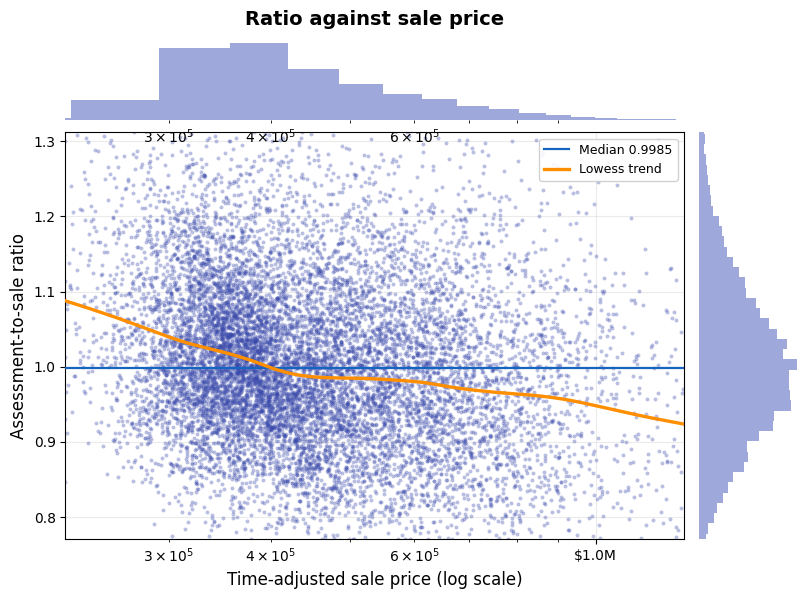

In [27]:
rs.asr_scatter(sample_df,
               assessment_header=ASSESSMENT,
               market_value_header=MARKET_VALUE,
               x=MARKET_VALUE,
               log_x=True,
               x_label='Time-adjusted sale price (log scale)',
               title='Ratio against sale price')

**Zooming.** `zoom=True` (the default) trims both axes to where the points actually are —
the 1st–99th percentile of the x variable, and 95% coverage of the ratios inside that
window — the same treatment the VEM chart uses. Without it, a handful of very large sales
and one ratio of 6 take most of the plot area and squeeze the cloud that carries the
finding into a corner. The median line is always kept in view, so zooming can never hide
the statistic the chart is about.

Note also that these charts no longer draw the 0.90–1.10 acceptance band. On a scatter of
individual sales the band invites exactly the reading the Standard warns against — judging single
properties against a standard that describes a population. The median line stays.

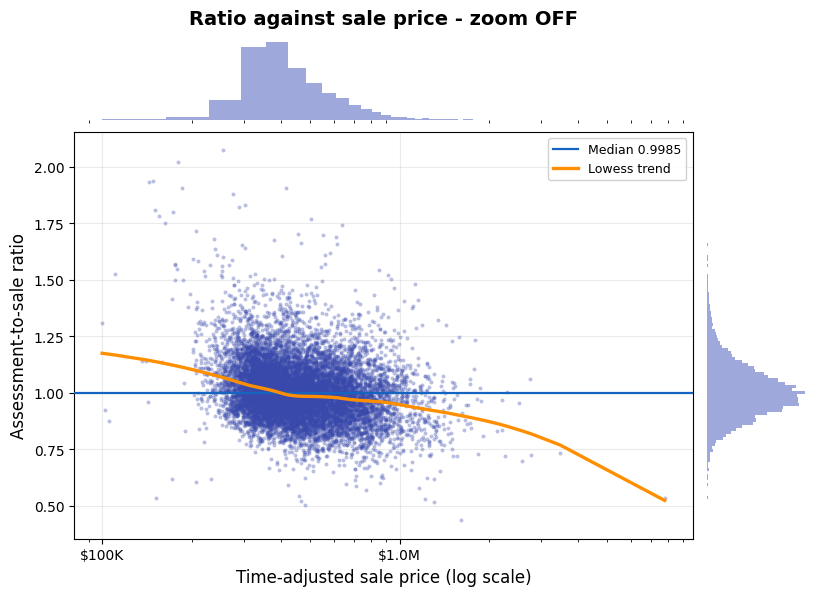

In [28]:
rs.asr_scatter(sample_df,
               assessment_header=ASSESSMENT,
               market_value_header=MARKET_VALUE,
               x=MARKET_VALUE,
               log_x=True,
               zoom=False,                      # the full range, tails and all
               x_label='Time-adjusted sale price (log scale)',
               title='Ratio against sale price - zoom OFF')

The same data with the default zoom is the chart above: same cloud, but readable. The
marginal histograms also carry more buckets now (`marginal_bins=120`), so the shape of both
distributions is visible rather than blocky.

The same chart against a property characteristic answers a different question: is the model
mis-pricing a *feature* rather than a price level? The Standard asks for exactly this check —
consistency across size groups, age groups and geographic areas — **before** a formal
vertical equity analysis.

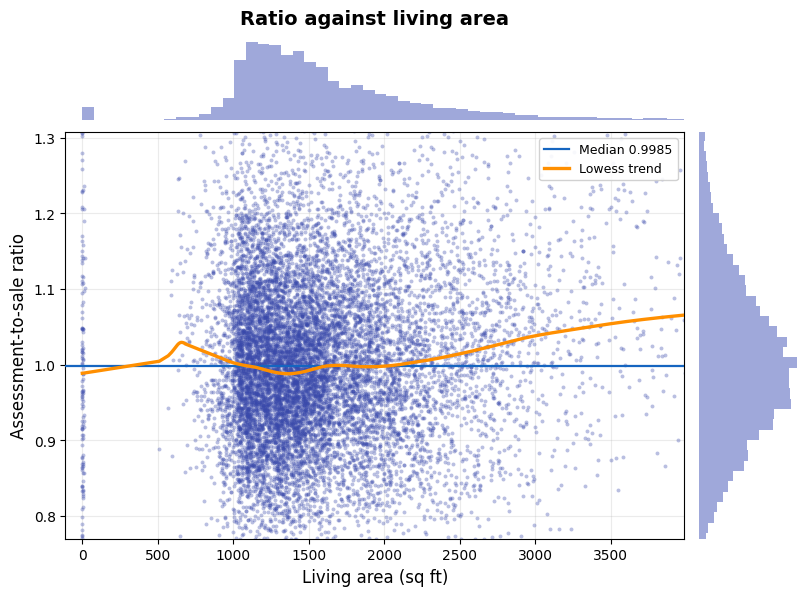

In [29]:
rs.asr_scatter(sample_df,
               assessment_header=ASSESSMENT,
               market_value_header=MARKET_VALUE,
               x='living_area',
               x_label='Living area (sq ft)',
               title='Ratio against living area')

### Histogram — the shape of the distribution

The Standard asks the analyst to examine the distribution *first*: performance measures built on
the mean or standard deviation mislead when the sample is not normal, and ratio study
samples typically are not. A bimodal histogram is the fastest way to see that two
populations have been mixed.

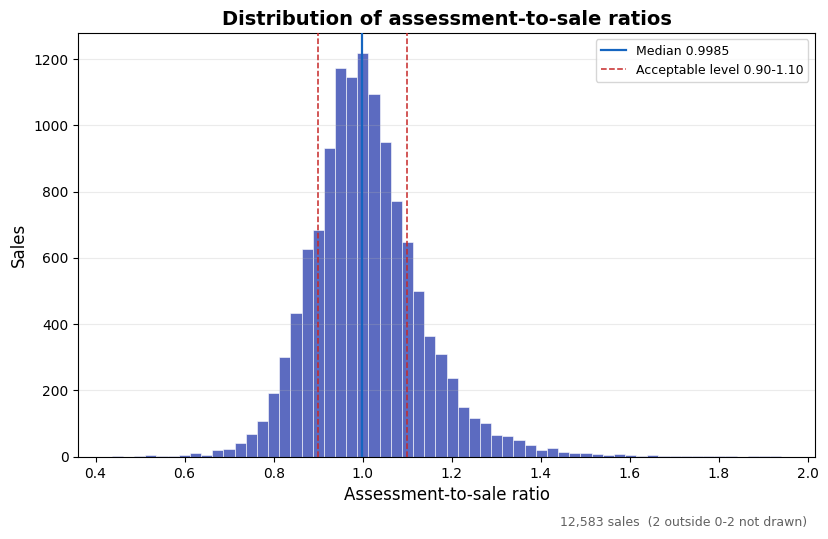

In [30]:
rs.asr_histogram(sample_df,
                 assessment_header=ASSESSMENT,
                 market_value_header=MARKET_VALUE,
                 bins=60,
                 title='Distribution of assessment-to-sale ratios')

### Boxplot by stratum — horizontal equity at a glance

The visual form of a grouped ratio table, and the chart type the Standard illustrates. Boxes at different **heights** are differing levels of valuation between strata
— the Standard's five-percent test. Boxes of different **sizes** are differing uniformity —
the COD story.

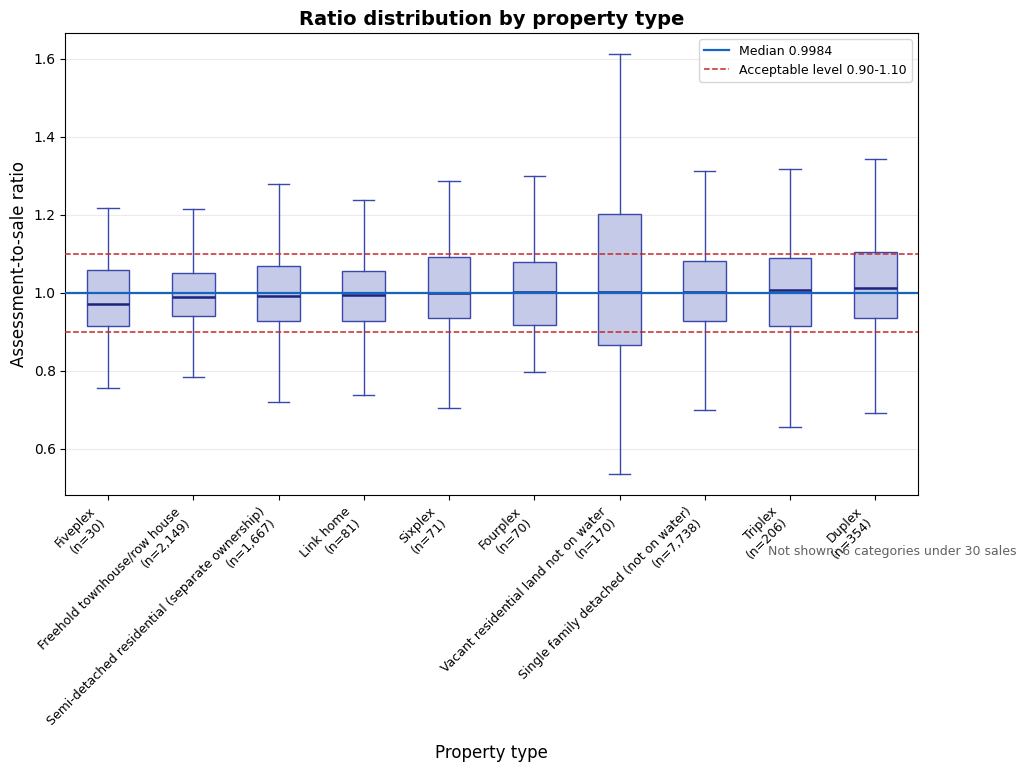

In [31]:
rs.asr_boxplot(sample_df,
               assessment_header=ASSESSMENT,
               market_value_header=MARKET_VALUE,
               by='property_type',
               min_count=30,
               order_by='median',
               title='Ratio distribution by property type')

`show_values=True` prints each group's median ratio above its box. The box shows the shape;
the number is what goes into the report — and the test a reader is actually making
is each stratum's level against the overall one, which is far easier to do with the figures
on the chart.

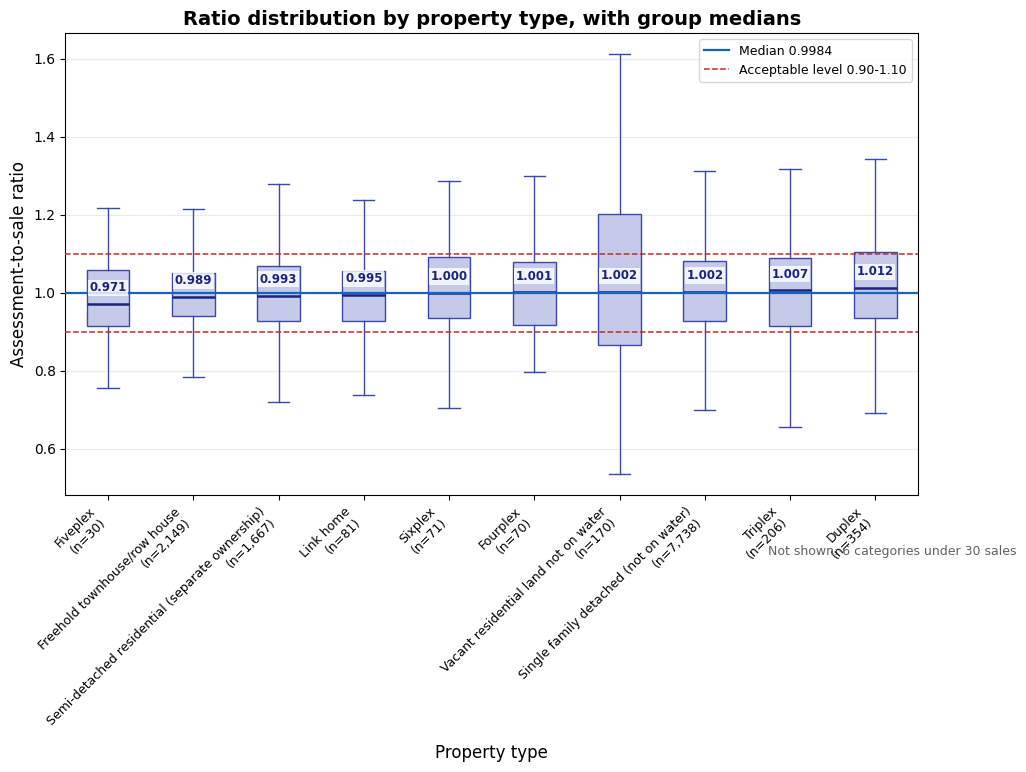

In [32]:
rs.asr_boxplot(sample_df,
               assessment_header=ASSESSMENT,
               market_value_header=MARKET_VALUE,
               by='property_type',
               min_count=30,
               order_by='median',
               show_values=True,                # value_fmt='{:.1%}' for percentages
               title='Ratio distribution by property type, with group medians')

### Facet grid — small multiples

An overall scatter can look flat while individual neighbourhoods each slope hard in
opposite directions. Faceting is how that shows up: the same axes repeated across strata,
compared by eye against a shared reference line.

asr_facet: 6 quality_class panel(s) not displayed -- fewer than 30 records, too few to read a pattern from:
  quality_class=1 : 1 record(s)
  quality_class=2 : 3 record(s)
  quality_class=10 : 10 record(s)
  quality_class=11 : 1 record(s)
  quality_class=12 : 1 record(s)
  quality_class=13 : 1 record(s)


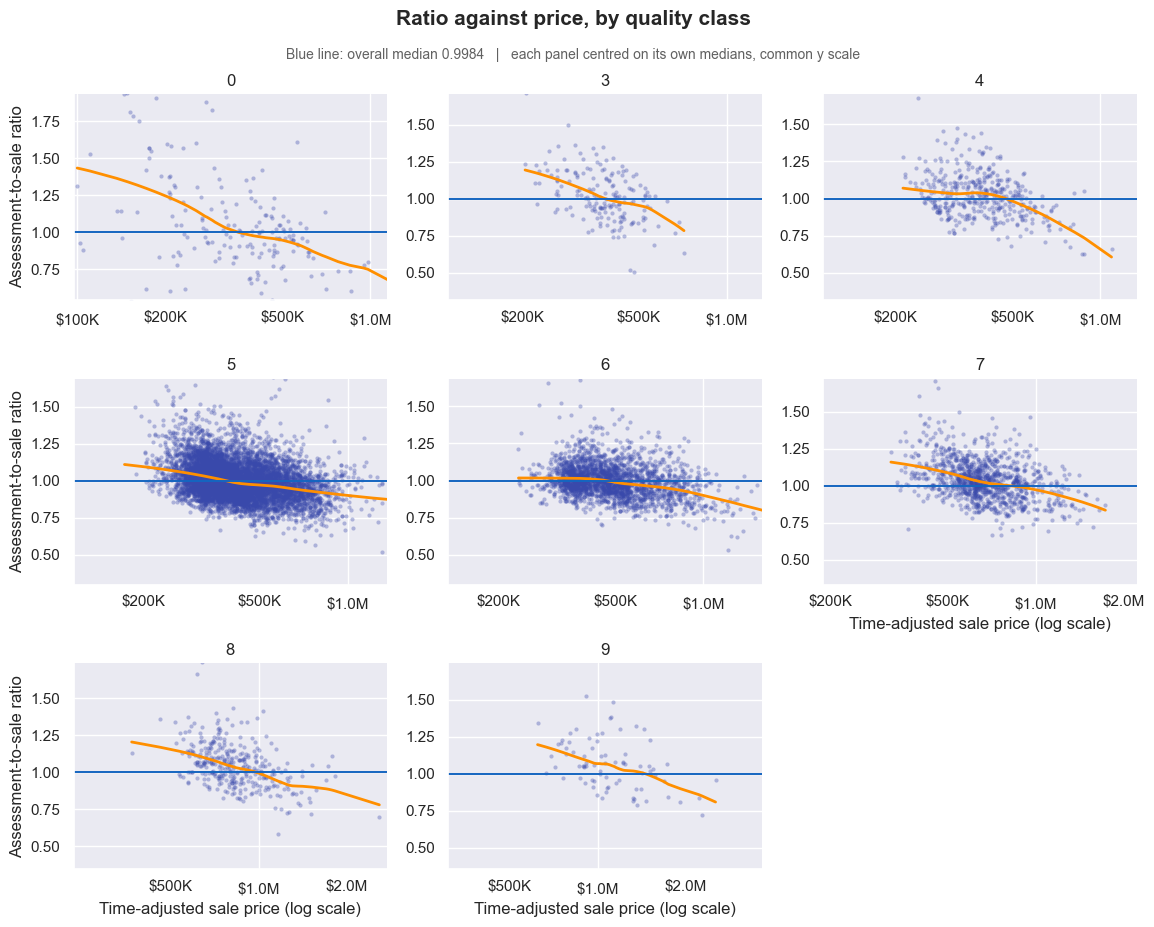

In [33]:
rs.asr_facet(sample_df,
             assessment_header=ASSESSMENT,
             market_value_header=MARKET_VALUE,
             x=MARKET_VALUE,
             col='quality_class',
             col_wrap=3,
             max_facets=9,
             log_x=True,
             x_label='Time-adjusted sale price (log scale)',
             title='Ratio against price, by quality class')

`row=` adds a second faceting dimension, for a true cross-tabulated grid.

asr_facet: 22 condition / quality_class panel(s) not displayed -- fewer than 30 records, too few to read a pattern from:
  condition=average, quality_class=1 : 1 record(s)
  condition=average, quality_class=2 : 2 record(s)
  condition=average, quality_class=10 : 10 record(s)
  condition=average, quality_class=11 : 1 record(s)
  condition=average, quality_class=12 : 1 record(s)
  condition=average, quality_class=13 : 1 record(s)
  condition=fair, quality_class=3 : 5 record(s)
  condition=fair, quality_class=4 : 9 record(s)
  condition=fair, quality_class=6 : 7 record(s)
  condition=fair, quality_class=7 : 2 record(s)
  condition=fair, quality_class=8 : 1 record(s)
  condition=fair, quality_class=9 : 2 record(s)
  condition=good, quality_class=3 : 4 record(s)
  condition=good, quality_class=4 : 8 record(s)
  condition=good, quality_class=6 : 6 record(s)
  condition=good, quality_class=8 : 2 record(s)
  condition=poor, quality_class=2 : 1 record(s)
  condition=poor, quality_class=3 : 3 re

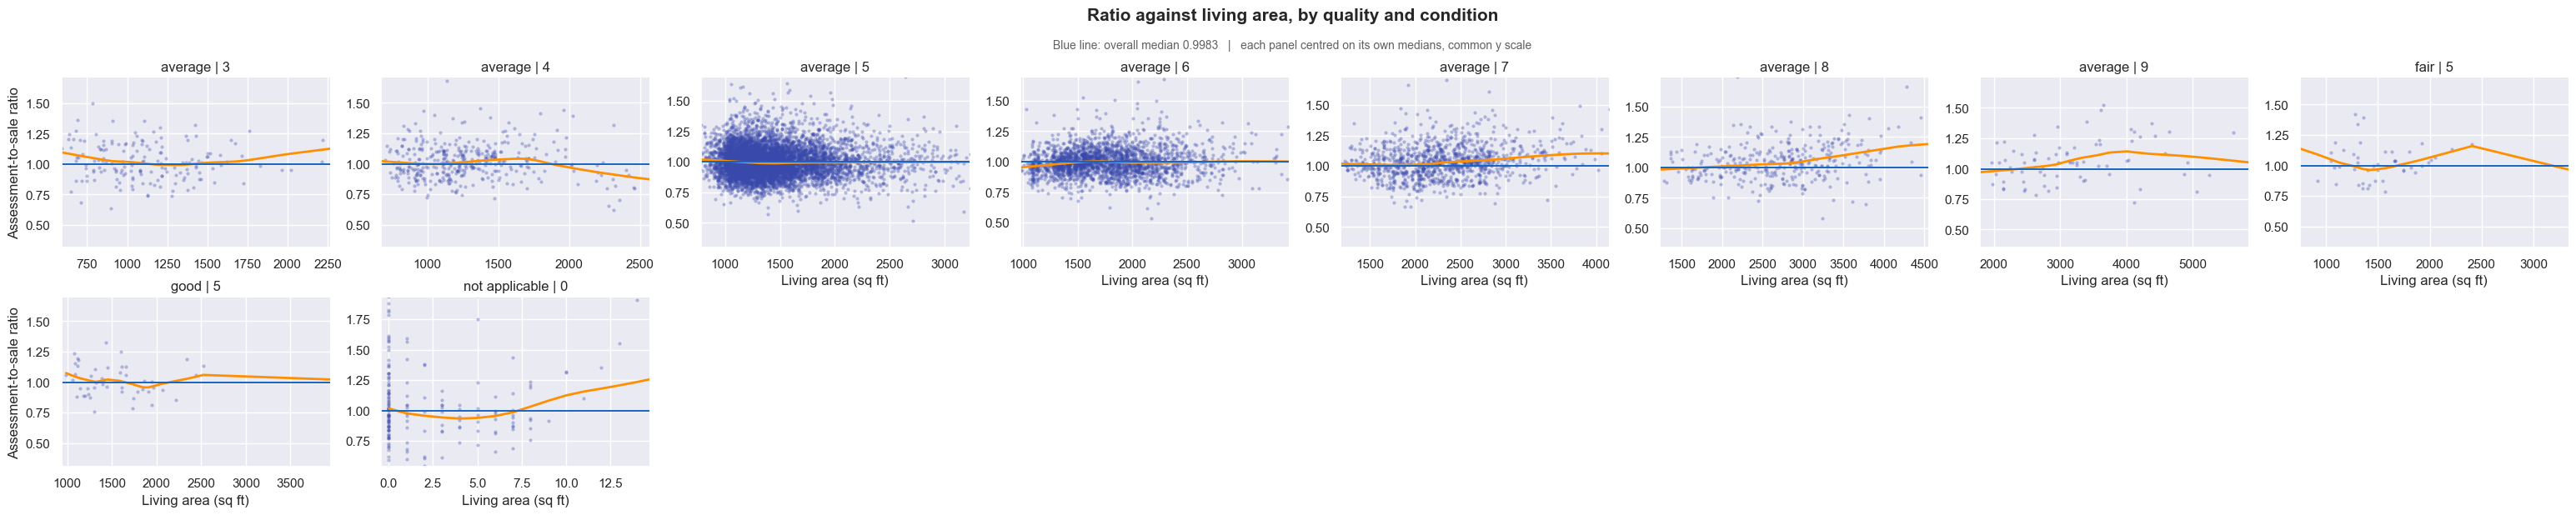

In [34]:
rs.asr_facet(sample_df,
             assessment_header=ASSESSMENT,
             market_value_header=MARKET_VALUE,
             x='living_area',
             col='quality_class',
             row='condition',
             max_facets=12,
             x_label='Living area (sq ft)',
             title='Ratio against living area, by quality and condition')

`asr_facet` takes the same `zoom` argument, and applies one trimmed range across **all**
panels — a small-multiples grid is only useful if the panels are comparable, so the limits
are measured on the whole frame rather than per panel. Set `zoom=False` to see the full
range in each.

asr_facet: 6 quality_class panel(s) not displayed -- fewer than 30 records, too few to read a pattern from:
  quality_class=1 : 1 record(s)
  quality_class=2 : 3 record(s)
  quality_class=10 : 10 record(s)
  quality_class=11 : 1 record(s)
  quality_class=12 : 1 record(s)
  quality_class=13 : 1 record(s)


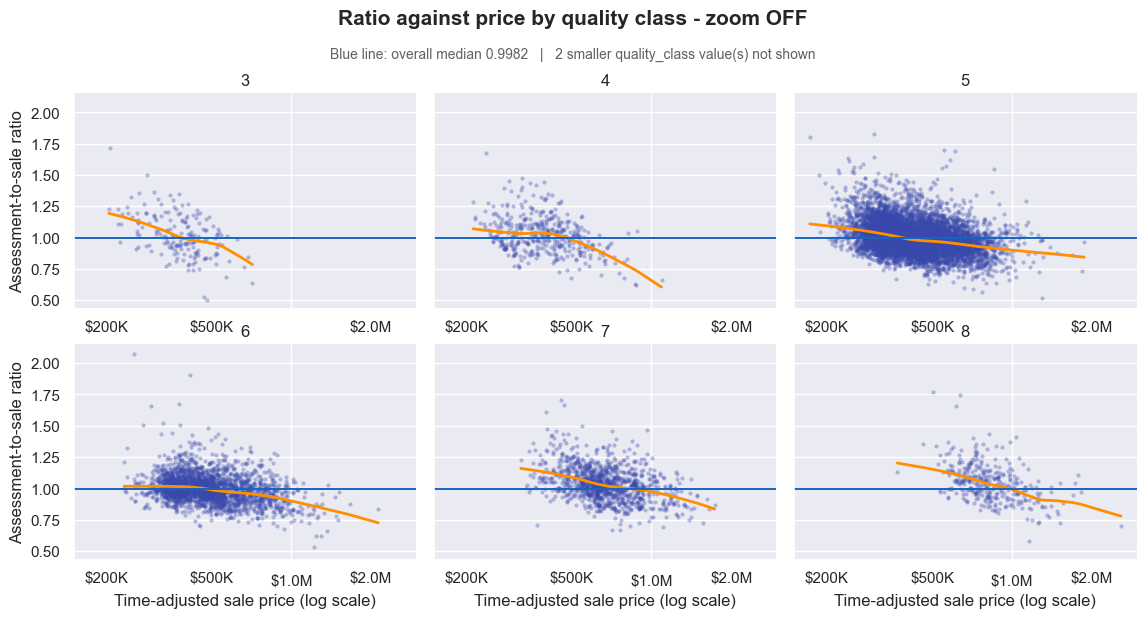

In [35]:
rs.asr_facet(sample_df,
             assessment_header=ASSESSMENT,
             market_value_header=MARKET_VALUE,
             x=MARKET_VALUE,
             col='quality_class',
             col_wrap=3,
             max_facets=6,
             log_x=True,
             zoom=False,                        # compare with the zoomed grid above
             x_label='Time-adjusted sale price (log scale)',
             title='Ratio against price by quality class - zoom OFF')

### The report's own chart family

`ratios()` can also build the charts destined for the PDF. These come back as report
flowables under `overall_graphs` rather than as inline figures.

Confidence interval settings  (<-- marks a value you set or is a default setting)
  Mode                  : distribution
  Level                 : 90%
  Indicators            : Median, Mean, Weighted_Mean, CoD, PRB, PRD
  Overall intervals     : on
  Per-group intervals   : off
  Minimum sales per row : 20
  Estimators            : Appendix D closed forms, plus PRB (regression) and PRD (delta method); bootstrap options ignored
VEI quantile method: R7


result keys : ['exported_files', 'dict_population_ratios', 'overall_graphs', 'group_mosaic_graphs', 'group_graphs', 'dist_plot_group_mosaic_graphs', 'histogram_overall_graphs', 'df_all_ratios', 'df_all_ratios_formatted', 'error_messages']
charts built: 4


<Figure size 1200x1000 with 0 Axes>

<Figure size 1200x1000 with 0 Axes>

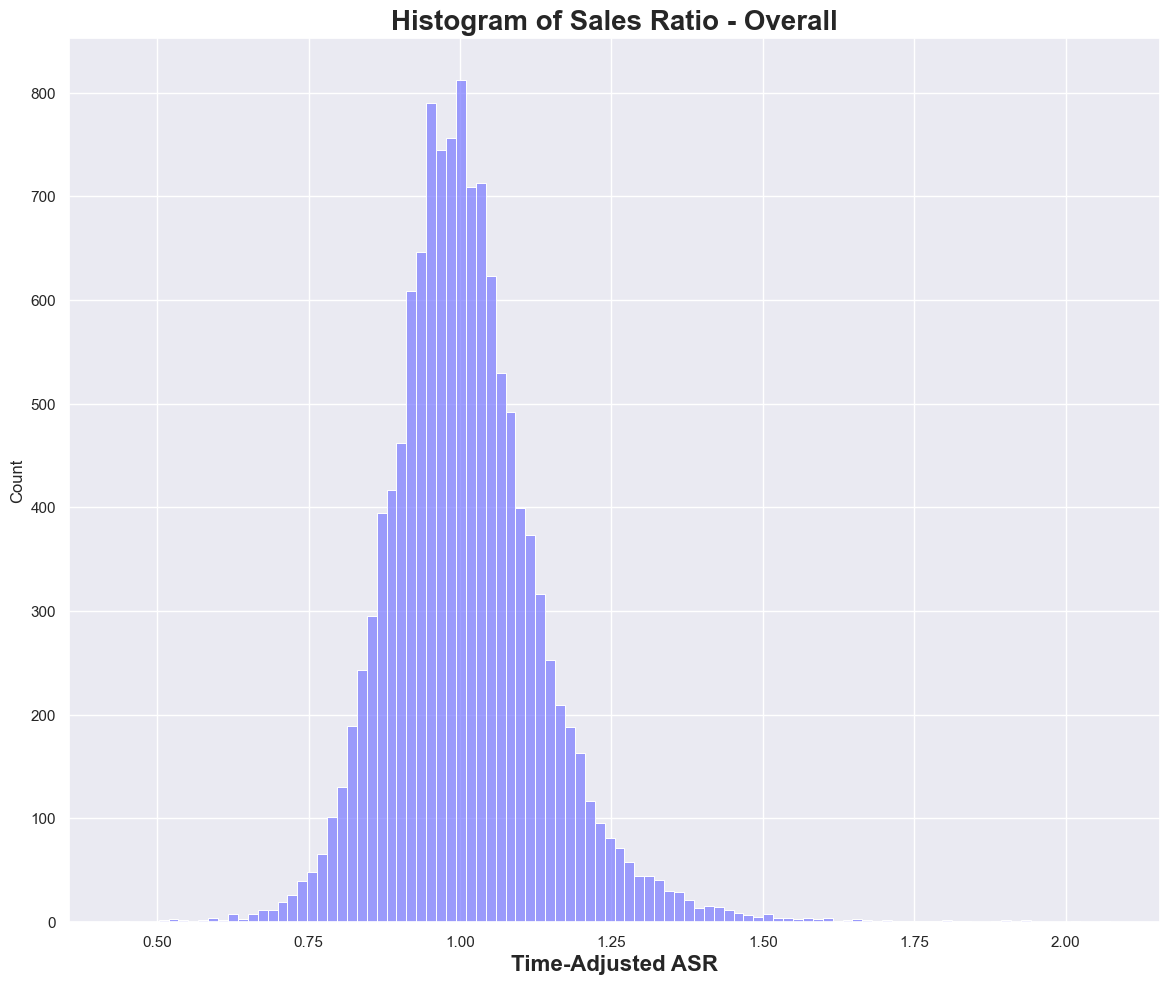

In [36]:
charted = rs.ratios(sample_df,
                    assessment_header=ASSESSMENT,
                    market_value_header=MARKET_VALUE,
                    return_dict=True,
                    graphs_args={'pdf_overall_asr_graphs': True,
                                 'pdf_asr_graphs_x_vars_and_aliases': {
                                     'overall': {'living_area':   'Living area (sq ft)',
                                                 'quality_class': 'Quality class',
                                                 'sale_month':    'Month of sale'},
                                     'overall_histogram': True,
                                     'groups': [], 'groups_mosaic': []}})

print('result keys :', list(charted.keys()))
print('charts built:', len(charted['overall_graphs']))

## 2.9 Visualisations — tables

`return_dict=True` gives the study as data rather than as a presentation object.
`df_all_ratios` is the raw numeric frame; `df_all_ratios_formatted` is the display version,
in which anything not computed is a **blank string rather than `NaN`** — a blank reads as
"not computed here", where `NaN` reads as a result.

In [37]:
by_quality_class = rs.ratios(sample_df,
                    assessment_header=ASSESSMENT,
                    market_value_header=MARKET_VALUE,
                    group_by='quality_class',
                    indicators=['Median', 'CoD', 'VEI', 'PRB'],
                    return_dict=True)

by_quality_class['df_all_ratios']

Confidence interval settings  (<-- marks a value you set or is a default setting)
  Mode                  : distribution
  Level                 : 90%
  Indicators            : Median, CoD, PRB   <-- set
  Overall intervals     : on
  Per-group intervals   : off
  Minimum sales per row : 20
  Estimators            : Appendix D closed forms, plus PRB (regression) and PRD (delta method); bootstrap options ignored
VEI quantile method: R7


,Level,Group,Count,Median,Median_ci,CoD,CoD_ci,PRB,PRB_ci,VEI,VEI_conclusion,VEI_kw_statistic,VEI_kw_pvalue,VEI_sig
0,Overall,,12583,0.998505,"(0.9967650365891872, 1.0001283036620632)",0.094821,"(0.09356253291774289, 0.09612268436647978)",-0.01777,"(-0.021590543867791846, -0.013947640232739223)",-0.747629,Acceptable,103.188706,3.557946e-18,0.000000
1,quality_class,0,172,0.998248,NaN,0.225006,NaN,-0.11515,NaN,-19.370293,Acceptable,11.485274,9.371420e-03,5.856670
2,quality_class,1,1,0.891571,NaN,NaN,NaN,NaN,NaN,0.000000,Sample size too small,NaN,NaN,0.000000
3,quality_class,2,3,1.015875,NaN,NaN,NaN,NaN,NaN,0.000000,Sample size too small,NaN,NaN,0.000000
4,quality_class,3,172,1.011813,NaN,0.131686,NaN,-0.0909,NaN,-9.268352,Acceptable,13.168996,4.285036e-03,1.911362
5,quality_class,4,401,1.010704,NaN,0.113534,NaN,-0.0482,NaN,-2.666135,Acceptable,16.753326,7.942805e-04,0.000000
6,quality_class,5,7966,0.994149,NaN,0.091190,NaN,-0.03839,NaN,-3.502310,Acceptable,245.375997,9.438581e-48,2.239429
7,quality_class,6,2365,0.993241,NaN,0.082647,NaN,-0.03252,NaN,-2.212058,Acceptable,89.305594,2.243671e-15,0.127718
8,quality_class,7,1072,1.028262,NaN,0.098389,NaN,-0.05681,NaN,-5.754960,Acceptable,33.501129,1.092081e-04,2.230860
9,quality_class,8,340,1.039353,NaN,0.109400,NaN,-0.0927,NaN,-7.725608,Acceptable,24.191433,2.278348e-05,3.486514


In [38]:
by_quality_class['df_all_ratios_formatted']

,Level,Group,Count,Median,Median_ci,CoD,CoD_ci,PRB,PRB_ci,VEI,VEI_conclusion,VEI_kw_statistic,VEI_kw_pvalue
0,Overall,,"12,583",0.9985,"(0.9968, 1.0001)",9.48%,"(9.36%, 9.61%)",-0.0178,"(-0.0216, -0.0139)",-0.75,Acceptable,103.19,0.00
1,quality_class,0,172,0.9982,,22.50%,,-0.1152,,-19.37,Acceptable,11.49,0.01
2,quality_class,1,1,0.8916,,,,,,0.00,Sample size too small,,
3,quality_class,2,3,1.0159,,,,,,0.00,Sample size too small,,
4,quality_class,3,172,1.0118,,13.17%,,-0.0909,,-9.27,Acceptable,13.17,0.00
5,quality_class,4,401,1.0107,,11.35%,,-0.0482,,-2.67,Acceptable,16.75,0.00
6,quality_class,5,"7,966",0.9941,,9.12%,,-0.0384,,-3.50,Acceptable,245.38,0.00
7,quality_class,6,"2,365",0.9932,,8.26%,,-0.0325,,-2.21,Acceptable,89.31,0.00
8,quality_class,7,"1,072",1.0283,,9.84%,,-0.0568,,-5.75,Acceptable,33.50,0.00
9,quality_class,8,340,1.0394,,10.94%,,-0.0927,,-7.73,Acceptable,24.19,0.00


## 2.10 The ratios comparison tool

The question a modeller actually asks is *"did my change help?"*. `compare_ratios()` takes
two studies and lays them side by side with the difference and the percentage change.
The Standard recommends exactly this when a study is one in a series.

First, the obvious use: the previous model versus the current one, on the same sales.

In [39]:
old_model = rs.ratios(sample_df, assessment_header=PRIOR_MODEL,
                      market_value_header=MARKET_VALUE, return_dict=True, print_ci_settings=False)
new_model = rs.ratios(sample_df, assessment_header=ASSESSMENT,
                      market_value_header=MARKET_VALUE, return_dict=True, print_ci_settings=False)

rs.compare_ratios(old_model, new_model,
                  suffixes=('_old', '_new'),
                  difference=True, pct_chg=True)

,Level,Group,Count_old,Count_new,Count_diff,Count_%,Median_old,Median_new,Median_diff,Median_%,Median_ci_old,Median_ci_new,Mean_old,Mean_new,Mean_diff,Mean_%,Mean_ci_old,Mean_ci_new,Weighted_Mean_old,Weighted_Mean_new,Weighted_Mean_diff,Weighted_Mean_%,Weighted_Mean_ci_old,Weighted_Mean_ci_new,CoD_old,CoD_new,CoD_diff,CoD_%,CoD_ci_old,CoD_ci_new,PRB_old,PRB_new,PRB_diff,PRB_%,PRB_ci_old,PRB_ci_new,PRB_ci_diff,PRB_ci_%,PRD_old,PRD_new,PRD_diff,PRD_%,PRD_ci_old,PRD_ci_new,VEI_old,VEI_new,VEI_diff,VEI_%,VEI_conclusion_old,VEI_conclusion_new,VEI_kw_statistic_old,VEI_kw_statistic_new,VEI_kw_statistic_diff,VEI_kw_statistic_%,VEI_kw_pvalue_old,VEI_kw_pvalue_new,VEI_kw_pvalue_diff,VEI_kw_pvalue_%,Inequity_conclusion_old,Inequity_conclusion_new,Inequity_severity_old,Inequity_severity_new,Inequity_severity_diff,Inequity_severity_%,Inequity_prevalence_old,Inequity_prevalence_new,Inequity_prevalence_diff,Inequity_prevalence_%,VEI_sig_old,VEI_sig_new,VEI_sig_diff,VEI_sig_%
0,Overall,,12583,12583,-,-,0.935056,0.998505,0.0634↑,6.7856%↑,"(0.9334992367050754, 0.9364835926631119)","(0.9967650365891872, 1.0001283036620632)",0.951031,1.008907,0.0579↑,6.0856%↑,"(0.9481388534104817, 0.9539235122022621)","(1.0070195130969282, 1.0107944489093383)",0.933541,0.996931,0.0634↑,6.7903%↑,"(0.9308731235532886, 0.9362085827082791)","(0.9945962840476321, 0.9992659126369903)",0.105165,0.094821,-0.0103↓,-9.8355%↓,"(0.10253234931784021, 0.10789714998873198)","(0.09356253291774289, 0.09612268436647978)",-0.00843,-0.01777,-0.0093↓,110.7948%↑,"(-0.014754437082721658, -0.002099225256392068)","(-0.021590543867791846, -0.013947640232739223)",-,-,1.018735,1.012013,-0.0067↓,-0.6599%↓,"(1.016813664108923, 1.0206572823781674)","(1.0106690707799983, 1.0133564264298598)",-3.782075,-0.747629,3.0344↑,-80.2323%↓,Acceptable,Acceptable,181.562254,103.188706,-78.3735↓,-43.1662%↓,2.390441e-34,3.557946e-18,0.0↑,1.4884058523564275e+18%↑,acceptable,acceptable,0.0,0.0,-,-,0.0,0.0,-,-,1.844822,0.0,-1.8448↓,-100.0%↓


It also works across different sales counts, so it can answer *"what did the outlier trim
actually do?"* — the before/after comparison the Standard effectively asks for.

In [40]:
before_trim = rs.ratios(sample_df, assessment_header=ASSESSMENT,
                        market_value_header=MARKET_VALUE, return_dict=True, print_ci_settings=False)
after_trim  = rs.ratios(sample_df, assessment_header=ASSESSMENT,
                        market_value_header=MARKET_VALUE, return_dict=True, print_ci_settings=False,
                        iqr_trim_multiple=3)

rs.compare_ratios(before_trim, after_trim,
                  suffixes=('_no_filter', '_iqr3'),
                  difference=True, pct_chg=True)

If you'd like to save the trimmed sales for audit, pass argument `iqr_filter_result='save'` or `iqr_filter_result='/path/to/file.csv.gz'`
IQR filter - trimmed sales
  Sales trimmed          : 34 of 12,583 (0.27%)
  Total trimmed assessment value : 20.7M of 6.1B (0.34%)
  Total trimmed market value     : 23.6M of 6.1B (0.39%)


,Level,Group,Count_no_filter,Count_iqr3,Count_diff,Count_%,Median_no_filter,Median_iqr3,Median_diff,Median_%,Median_ci_no_filter,Median_ci_iqr3,Mean_no_filter,Mean_iqr3,Mean_diff,Mean_%,Mean_ci_no_filter,Mean_ci_iqr3,Weighted_Mean_no_filter,Weighted_Mean_iqr3,Weighted_Mean_diff,Weighted_Mean_%,Weighted_Mean_ci_no_filter,Weighted_Mean_ci_iqr3,CoD_no_filter,CoD_iqr3,CoD_diff,CoD_%,CoD_ci_no_filter,CoD_ci_iqr3,PRB_no_filter,PRB_iqr3,PRB_diff,PRB_%,PRB_ci_no_filter,PRB_ci_iqr3,PRB_ci_diff,PRB_ci_%,PRD_no_filter,PRD_iqr3,PRD_diff,PRD_%,PRD_ci_no_filter,PRD_ci_iqr3,VEI_no_filter,VEI_iqr3,VEI_diff,VEI_%,VEI_conclusion_no_filter,VEI_conclusion_iqr3,VEI_kw_statistic_no_filter,VEI_kw_statistic_iqr3,VEI_kw_statistic_diff,VEI_kw_statistic_%,VEI_kw_pvalue_no_filter,VEI_kw_pvalue_iqr3,VEI_kw_pvalue_diff,VEI_kw_pvalue_%,Inequity_conclusion_no_filter,Inequity_conclusion_iqr3,Inequity_severity_no_filter,Inequity_severity_iqr3,Inequity_severity_diff,Inequity_severity_%,Inequity_prevalence_no_filter,Inequity_prevalence_iqr3,Inequity_prevalence_diff,Inequity_prevalence_%,VEI_sig_no_filter,VEI_sig_iqr3,VEI_sig_diff,VEI_sig_%
0,Overall,,12583,12549,-34↓,-0.2702%↓,0.998505,0.998388,-0.0001↓,-0.0117%↓,"(0.9967650365891872, 1.0001283036620632)","(0.9966348850252383, 1.0000393797501823)",1.008907,1.00804,-0.0009↓,-0.086%↓,"(1.0070195130969282, 1.0107944489093383)","(1.0062250834506545, 1.0098545132676429)",0.996931,0.997405,0.0005↑,0.0475%↑,"(0.9945962840476321, 0.9992659126369903)","(0.9953348452668829, 0.9994745392792097)",0.094821,0.093246,-0.0016↓,-1.6612%↓,"(0.09356253291774289, 0.09612268436647978)","(0.0920727072924968, 0.09445633684968105)",-0.01777,-0.01537,0.0024↑,-13.5059%↓,"(-0.021590543867791846, -0.013947640232739223)","(-0.019061431006423497, -0.011676259009813717)",-,-,1.012013,1.010663,-0.0013↓,-0.1334%↓,"(1.0106690707799983, 1.0133564264298598)","(1.009744624052216, 1.011580934506899)",-0.747629,-0.742864,0.0048↑,-0.6374%↓,Acceptable,Acceptable,103.188706,106.360006,3.1713↑,3.0733%↑,3.557946e-18,8.084801e-19,-0.0↓,-77.2768%↓,acceptable,acceptable,0.0,0.0,-,-,0.0,0.0,-,-,0.0,0.0,-,-


And it compares grouped studies, so you can find the strata a model change helped — and
the ones it hurt. Narrow the output with `indicators=`.

In [41]:
grouping = ['quality_class', 'property_type', ['quality_class', 'property_type']]

old_grouped = rs.ratios(sample_df, assessment_header=PRIOR_MODEL,
                        market_value_header=MARKET_VALUE,
                        group_by=grouping, return_dict=True, print_ci_settings=False)
new_grouped = rs.ratios(sample_df, assessment_header=ASSESSMENT,
                        market_value_header=MARKET_VALUE,
                        group_by=grouping, return_dict=True, print_ci_settings=False)

compared_ratios = rs.compare_ratios(old_grouped, new_grouped,
                                    suffixes=('_old', '_new'),
                                    difference=True, pct_chg=True,
                                    indicators=['Median', 'CoD', 'VEI'])
compared_ratios

,Level,Group,Median_old,Median_new,Median_diff,Median_%,CoD_old,CoD_new,CoD_diff,CoD_%,VEI_old,VEI_new,VEI_diff,VEI_%
0,Overall,,0.935056,0.998505,0.0634↑,6.7856%↑,0.105165,0.094821,-0.0103↓,-9.8355%↓,-3.782075,-0.747629,3.0344↑,-80.2323%↓
1,quality_class,0,0.887875,0.998248,0.1104↑,12.4311%↑,0.906292,0.225006,-0.6813↓,-75.1729%↓,170.623937,-19.370293,-189.9942↓,-111.3526%↓
2,quality_class,1,0.701259,0.891571,0.1903↑,27.1386%↑,NaN,NaN,-,-,0.000000,0.000000,-,-
3,quality_class,2,0.832887,1.015875,0.183↑,21.9702%↑,NaN,NaN,-,-,0.000000,0.000000,-,-
4,quality_class,3,0.887712,1.011813,0.1241↑,13.9799%↑,0.132363,0.131686,-0.0007↓,-0.5115%↓,3.794365,-9.268352,-13.0627↓,-344.2662%↓
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99,"quality_class, property_type","9, Duplex",0.882420,1.132070,0.2497↑,28.2915%↑,NaN,NaN,-,-,0.000000,0.000000,-,-
100,"quality_class, property_type","9, Freehold townhouse/row house",0.910396,0.966538,0.0561↑,6.1668%↑,0.124405,0.156762,0.0324↑,26.0093%↑,0.000000,0.000000,-,-
101,"quality_class, property_type","9, Semi-detached residential (separate ownership)",0.946795,1.069666,0.1229↑,12.9776%↑,0.066129,0.092990,0.0269↑,40.6184%↑,0.000000,0.000000,-,-
102,"quality_class, property_type","9, Single family detached (not on water)",0.950496,1.049752,0.0993↑,10.4426%↑,0.106997,0.113210,0.0062↑,5.8068%↑,-9.316611,-0.739072,8.5775↑,-92.0672%↓


In [42]:
rs.compare_ratios(old_grouped, new_grouped,
                                    suffixes=('_old', '_new'),
                                    difference=True, pct_chg=True,
                                    indicators=['Count', 'Median', 'CoD', 'VEI'])

,Level,Group,Count_old,Count_new,Count_diff,Count_%,Median_old,Median_new,Median_diff,Median_%,CoD_old,CoD_new,CoD_diff,CoD_%,VEI_old,VEI_new,VEI_diff,VEI_%
0,Overall,,12583,12583,-,-,0.935056,0.998505,0.0634↑,6.7856%↑,0.105165,0.094821,-0.0103↓,-9.8355%↓,-3.782075,-0.747629,3.0344↑,-80.2323%↓
1,quality_class,0,172,172,-,-,0.887875,0.998248,0.1104↑,12.4311%↑,0.906292,0.225006,-0.6813↓,-75.1729%↓,170.623937,-19.370293,-189.9942↓,-111.3526%↓
2,quality_class,1,1,1,-,-,0.701259,0.891571,0.1903↑,27.1386%↑,NaN,NaN,-,-,0.000000,0.000000,-,-
3,quality_class,2,3,3,-,-,0.832887,1.015875,0.183↑,21.9702%↑,NaN,NaN,-,-,0.000000,0.000000,-,-
4,quality_class,3,172,172,-,-,0.887712,1.011813,0.1241↑,13.9799%↑,0.132363,0.131686,-0.0007↓,-0.5115%↓,3.794365,-9.268352,-13.0627↓,-344.2662%↓
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99,"quality_class, property_type","9, Duplex",1,1,-,-,0.882420,1.132070,0.2497↑,28.2915%↑,NaN,NaN,-,-,0.000000,0.000000,-,-
100,"quality_class, property_type","9, Freehold townhouse/row house",8,8,-,-,0.910396,0.966538,0.0561↑,6.1668%↑,0.124405,0.156762,0.0324↑,26.0093%↑,0.000000,0.000000,-,-
101,"quality_class, property_type","9, Semi-detached residential (separate ownership)",7,7,-,-,0.946795,1.069666,0.1229↑,12.9776%↑,0.066129,0.092990,0.0269↑,40.6184%↑,0.000000,0.000000,-,-
102,"quality_class, property_type","9, Single family detached (not on water)",57,57,-,-,0.950496,1.049752,0.0993↑,10.4426%↑,0.106997,0.113210,0.0062↑,5.8068%↑,-9.316611,-0.739072,8.5775↑,-92.0672%↓


In [43]:
# Save the comparison for the model review pack.
compared_ratios.to_csv(results_directory / 'compared_ratios.csv', index=False)
print('written:', results_directory / 'compared_ratios.csv')

written: <path>